# Learn covariance correction by doing the matrix operations

A covariance describes how measurements fluctuate together. Its inverse,
the **precision**, supplies their weights in a fit. Friedrich and Eifler's
[precision-matrix expansion](https://arxiv.org/abs/1703.07786) starts with a
covariance model and uses simulations to estimate its missing terms.
Only the model covariance needs inversion.

We first calculate with four vectors and a two-by-two matrix. Each code cell
performs the step just explained, and prints its intermediate quantities.
We then check against the shared implementation and study a larger artificial
joint vector. The final sections explain the real-map experiment. This
notebook itself reads **no simulation maps**; the map pilot has its own
explicit driver and saved measurements.

Read the [notes](notes/covariance_from_simulations/covariance_from_simulations.pdf)
for the longer derivation. The main distinction throughout is between an
**observed estimate**, its **average over repeated experiments**, and the
usually unknown **true covariance**. An unbiased estimate can still be poor
in an individual experiment.

## 1. Set up a reproducible, bounded experiment

The wrapper constructs matrices and draws small Gaussian vectors. It imports
no native CosmoLike model and runs no CAMB calculation. The statistical estimators come from the shared
[precision module](../../external_modules/code/cosmolike_core/cosmolike_notebook_utils/covariance/precision.py),
which the forecast driver also uses. Training and validation have separate random-number streams, the
wrapper fixes the analytic model before drawing either stream, and the
experiment never replaces a draw because its estimate is inconvenient. BLAS
uses one worker, including in a reused notebook kernel.

In [1]:
# Setup only: this cell loads the plotting and statistical routines.
# No DES map, cosmological model or covariance calculation is started here.
# Run this notebook from the des_3pcf directory so the paths below refer to
# this checkout rather than another project's compiled interface.
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
from pathlib import Path
import sys
import importlib

# Set workers before importing NumPy. This small example needs one worker;
# BLAS must remain single-threaded in the Cocoa workflow.
for variable in (
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "OMP_NUM_THREADS",
):
    os.environ[variable] = "1"
PROJECT = Path.cwd()
if not (PROJECT / "README.md").is_file():
    raise ValueError("Use des_3pcf as this notebook's working directory.")
CORE = PROJECT.parents[1] / "external_modules" / "code" / "cosmolike_core"
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(CORE))
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from threadpoolctl import threadpool_info, threadpool_limits
from cosmolike_notebook_utils.covariance.precision import (
    component_precision_expansion,
    precision_expansion,
    split_precision_expansion,
    whiten_covariance,
)

# A notebook kernel may already have imported a BLAS library. Limit those
# loaded libraries too; environment variables alone would not change them.
blas_limit = threadpool_limits(limits=1, user_api="blas")
for library in threadpool_info():
    if library["user_api"] == "blas" and library["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS library has more than one worker.")
# The shared plotting package accepts ordinary arrays and does not run
# this project's native interface. Its name begins with a digit, so importlib
# loads it by its full module name.
plots = importlib.import_module(name="cosmolike_notebook_utils.3pcf")

In [2]:
# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90

## 2. Start with four measured vectors

Each row below represents one independent experiment, with two measurements.
The columns must have the same meaning in every row. First compute the mean
of each column:

$$\bar d_i=\frac{1}{N}\sum_{s=1}^N d_{si}.$$

Subtract this mean from each row to obtain a fluctuation:

$$r_{si}=d_{si}-\bar d_i.$$

A covariance entry measures whether two columns fluctuate together:

$$\widehat C_{ij}=\frac{1}{N-1}\sum_{s=1}^N r_{si}r_{sj}.$$

The denominator is $N-1$ because the same sample estimated its mean. In the
code, `residuals.T @ residuals` performs every pair of column products and
sums over the experiments. `@` means matrix multiplication; `**2` would
square individual entries and would not compute this covariance.

In [3]:
# Four small, deliberately chosen vectors make all the arithmetic visible.
# They teach the covariance calculation; they are not a Gaussian mock suite.
small_vectors = np.array([[1., 1.], [2., 1.], [3., 3.], [4., 3.]])
small_count = small_vectors.shape[0]
small_mean = np.mean(a=small_vectors, axis=0)
small_residuals = small_vectors - small_mean
small_products = small_residuals.T @ small_residuals
small_covariance = small_products / (small_count - 1)
print("Column means:", small_mean)
print("Mean-subtracted rows:\n", small_residuals)
print("Sum of outer products:\n", small_products)
print("Sample covariance:\n", small_covariance)
np.testing.assert_allclose(small_covariance, np.array([[5., 4.], [4., 4.]]) / 3.)

Column means: [2.5 2. ]
Mean-subtracted rows:
 [[-1.5 -1. ]
 [-0.5 -1. ]
 [ 0.5  1. ]
 [ 1.5  1. ]]
Sum of outer products:
 [[5. 4.]
 [4. 4.]]
Sample covariance:
 [[1.66666667 1.33333333]
 [1.33333333 1.33333333]]


## 3. Remove the model's units before comparing covariances

For the next example, imagine that ten independent Gaussian experiments gave
this sample covariance. It is a new example; it is not the four-row sample
above:

$$\widehat C=\begin{pmatrix}4.4&0.4\\0.4&0.9\end{pmatrix}.$$

Our independently specified model predicts

$$M=\begin{pmatrix}4&0\\0&1\end{pmatrix}.$$

Its first measurement has model standard deviation two, and its second has
standard deviation one. The Cholesky factor is the matrix whose product
with its transpose reconstructs the model:

$$M=LL^{\mathsf T}.$$

For this diagonal example, it records the two standard deviations:

$$L=\begin{pmatrix}2&0\\0&1\end{pmatrix}.$$

Dividing each fluctuation by its model scale is called **whitening**. For a
covariance, both the row and the column acquire a scale factor:

$$S=L^{-1}\widehat C L^{-\mathsf T}.$$

For example, its off-diagonal entry becomes

$$S_{12}=\frac{0.4}{2\times1}=0.2.$$

The resulting matrix is dimensionless. General correlated models use the
same operation with a triangular, rather than diagonal, Cholesky factor.

In [4]:
# These are observed example inputs. The true covariance is not specified.
# N counts independent vectors, not pixels, cuts or repeated noise files.
example_count = 10
example_sample = np.array([[4.4, 0.4], [0.4, 0.9]])
example_model = np.diag(v=[4., 1.])
example_identity = np.eye(N=2)
example_factor = np.linalg.cholesky(example_model)
# Solve L times X = I to display L^{-1} for this tiny teaching matrix.
# The shared production routine instead applies triangular solves directly.
example_inverse_factor = np.linalg.solve(example_factor, example_identity)
example_whitened = example_inverse_factor @ example_sample
example_whitened = example_whitened @ example_inverse_factor.T
print("L:\n", example_factor)
print("L inverse:\n", example_inverse_factor)
print("Whitened observed covariance S:\n", example_whitened)

L:
 [[2. 0.]
 [0. 1.]]
L inverse:
 [[0.5 0. ]
 [0.  1. ]]
Whitened observed covariance S:
 [[1.1 0.2]
 [0.2 0.9]]


## 4. Why the square needs its own correction

Call the unknown true covariance in these coordinates $R$:

$$R=L^{-1}CL^{-\mathsf T}.$$

Repeated independent experiments would give different observed matrices
$S$. Their ensemble average is $R$. The precision expansion needs the true
matrix square $R^2$, but simply squaring an observed $S$ also squares its
sampling error. This adds a bias even when $S$ itself is unbiased.

The scalar case makes the effect visible. Take a true dimensionless variance
of 1.1 and five independent Gaussian draws per experiment. After subtracting
the sample mean, the degrees of freedom are

$$\nu=N-1=4.$$

The Gaussian sample-variance identity gives

$$\mathbb E[S^2]=\left(1+\frac{2}{\nu}\right)R^2.$$

Its value is 1.815, although the square we want is only 1.21. Multiply the
observed square by the inverse bias factor:

$$Q=\frac{\nu}{\nu+2}S^2.$$

Now the **expectation** of $Q$ is 1.21. This says nothing about the exact value
of $Q$ in one experiment. We calculate ensemble expectations analytically
below; these printed values are not Monte Carlo estimates.

In [5]:
# The scalar example has its own N=5; it does not replace example_count=10.
scalar_truth = 1.1
scalar_nu = 5 - 1
expected_naive_square = (1. + 2. / scalar_nu) * scalar_truth**2
scalar_multiplier = scalar_nu / (scalar_nu + 2.)
expected_corrected_square = scalar_multiplier * expected_naive_square
print("True variance squared:", scalar_truth**2)
print("Expected observed square:", expected_naive_square)
print("Correction multiplier:", scalar_multiplier)
print("Expected corrected square:", expected_corrected_square)
# One observed S can happen to equal R, but its corrected square still differs.
print("Q for one observed S=1.1:", scalar_multiplier * 1.1**2)
np.testing.assert_allclose(expected_corrected_square, scalar_truth**2)

True variance squared: 1.2100000000000002
Expected observed square: 1.8150000000000004
Correction multiplier: 0.6666666666666666
Expected corrected square: 1.2100000000000002
Q for one observed S=1.1: 0.8066666666666668


## 5. Derive the matrix correction before computing it

Matrices have cross terms that the scalar multiplier cannot remove. For
independent Gaussian vectors, their sample covariance has a Wishart
distribution. Its moment identity for the matrix square is

$$\mathbb E[S^2]=\left(1+\frac{1}{\nu}\right)R^2
 +\frac{R\,\mathrm{tr}(R)}{\nu}.$$

Here the trace is the sum of the diagonal entries. The unwanted second term
contains that trace. A second observable product has exactly the trace
structure needed to cancel it:

$$\mathbb E[S\,\mathrm{tr}(S)]=R\,\mathrm{tr}(R)+\frac{2}{\nu}R^2.$$

Multiply the first identity by $\nu^2$. Multiply the second by $\nu$, then
subtract. The trace terms cancel, leaving

$$\mathbb E[\nu^2S^2-\nu S\,\mathrm{tr}(S)]
 =(\nu^2+\nu-2)R^2.$$

Dividing by the coefficient on the right defines the corrected square:

$$Q=\frac{\nu^2S^2-\nu S\,\mathrm{tr}(S)}{\nu^2+\nu-2}.$$

This requires $N>2$. It corrects an ensemble bias under the Gaussian and
independence assumptions. It neither removes the scatter of $Q$ nor turns
non-Gaussian shear summaries into Gaussian vectors.

### 5.1 Compute the ordinary square and the trace separately

Return to the ten-experiment matrix example. Matrix multiplication gives

$$S^2=\begin{pmatrix}1.25&0.40\\0.40&0.85\end{pmatrix}.$$

For example, the upper-left entry is the row-by-column product

$$(S^2)_{11}=1.1\times1.1+0.2\times0.2=1.25.$$

The trace is a single number:

$$\mathrm{tr}(S)=1.1+0.9=2.$$

Keeping these as separate named arrays makes the difference between matrix
and scalar multiplication visible in the code.

In [6]:
# Matrix multiplication includes off-diagonal products in the diagonal.
example_square = example_whitened @ example_whitened
# The trace is a scalar, so the next cell multiplies every entry by it.
example_trace = np.trace(a=example_whitened)
print("S squared by matrix multiplication:\n", example_square)
print("Trace of S:", example_trace)
print("Entrywise square, which would be WRONG here:\n", example_whitened**2)

S squared by matrix multiplication:
 [[1.25 0.4 ]
 [0.4  0.85]]
Trace of S: 2.0
Entrywise square, which would be WRONG here:
 [[1.21 0.04]
 [0.04 0.81]]


### 5.2 Form the two numerator terms

Ten experiments give nine degrees of freedom. The positive term is

$$\nu^2S^2=\begin{pmatrix}101.25&32.40\\32.40&68.85\end{pmatrix}.$$

The term to subtract is

$$\nu S\,\mathrm{tr}(S)=\begin{pmatrix}19.80&3.60\\3.60&16.20\end{pmatrix}.$$

Subtract corresponding entries, then divide every entry by the same
normalization:

$$\nu^2+\nu-2=9^2+9-2=88.$$

The subtraction removes the ensemble bias of the square. It does not
subtract a physical noise covariance from the measurement.

In [7]:
example_nu = example_count - 1
example_positive_term = example_nu**2 * example_square
example_subtraction = example_nu * example_trace * example_whitened
example_numerator = example_positive_term - example_subtraction
example_denominator = example_nu**2 + example_nu - 2.
example_corrected_square = example_numerator / example_denominator
print("Positive term:\n", example_positive_term)
print("Term subtracted:\n", example_subtraction)
print("Numerator:\n", example_numerator)
print("Denominator:", example_denominator)
print("Corrected square Q:\n", example_corrected_square)
np.testing.assert_allclose(
    example_corrected_square,
    np.array([[81.45, 28.8], [28.8, 52.65]]) / 88.,
)

Positive term:
 [[101.25  32.4 ]
 [ 32.4   68.85]]
Term subtracted:
 [[19.8  3.6]
 [ 3.6 16.2]]
Numerator:
 [[81.45 28.8 ]
 [28.8  52.65]]
Denominator: 88.0
Corrected square Q:
 [[0.92556818 0.32727273]
 [0.32727273 0.59829545]]


## 6. Build the precision and restore the original units

The true residual is the discrepancy from the whitened model:

$$X=R-I.$$

If every eigenvalue of $X$ has magnitude below one, the inverse has a
convergent series. Retaining terms through second order gives

$$(I+X)^{-1}\simeq I-X+X^2.$$

Replacing $X$ by $R-I$ and expanding the brackets gives

$$I-(R-I)+(R-I)^2=3I-3R+R^2.$$

We estimate the linear term with $S$ and the square with $Q$:

$$\widehat P_2=3I-3S+Q.$$

This is a dimensionless precision estimate. A residual in original units
must first be whitened on both sides of its quadratic weight. Therefore
restore the physical precision as

$$\widehat\Psi_2=L^{-\mathsf T}\widehat P_2L^{-1}.$$

The transpose is on the **left** here. Compare with the covariance
transformation earlier; the two orders are different.

In [8]:
# Keep the linear part separate so the reader can see where Q enters.
example_linear_part = 3. * example_identity - 3. * example_whitened
example_polynomial = example_linear_part + example_corrected_square
example_precision = example_inverse_factor.T @ example_polynomial
example_precision = example_precision @ example_inverse_factor
print("3I - 3S:\n", example_linear_part)
print("Dimensionless second-order precision:\n", example_polynomial)
print("Precision in original measurement units:\n", example_precision)
# A valid Gaussian weight must be positive in every direction. Do not clip
# negative eigenvalues to make a failed correction look acceptable.
print("Polynomial eigenvalues:", np.linalg.eigvalsh(example_polynomial))
shared_precision, shared_diagnostics = precision_expansion(
    analytic=example_model,
    sample=example_sample,
    independent_count=example_count,
    order=2,
)
np.testing.assert_allclose(shared_precision, example_precision, rtol=1.e-13)
print("The shared routine agrees with the displayed operations.")

3I - 3S:
 [[-0.3 -0.6]
 [-0.6  0.3]]
Dimensionless second-order precision:
 [[ 0.62556818 -0.27272727]
 [-0.27272727  0.89829545]]
Precision in original measurement units:
 [[ 0.15639205 -0.13636364]
 [-0.13636364  0.89829545]]
Polynomial eigenvalues: [0.45701346 1.06685018]
The shared routine agrees with the displayed operations.


**What this check establishes.** We obtained approximately 0.156392,
and 0.898295 on the diagonal, and −0.136364 off the diagonal. These are
the entries of the restored precision. The check verifies the arithmetic and the call to
the shared routine. We did not specify the true covariance for these ten
experiments, so we cannot infer that this correction improves it.

Three different questions remain: Is the covariance model close enough for
the series to converge? Are the Gaussian sampling identities appropriate?
Are there enough independent simulations to keep the correction's scatter
small? A positive estimate alone does not answer these questions.

## 7. Define what is known and what simulations must estimate

For the larger experiment, the true covariance is

$$C=A+B.$$

Both terms are covariances of random contributions to the same full data
vector. The model retains the known term and approximates the other:

$$M=A+B_m.$$

Here $A$ is known, and $B_m$ imperfectly approximates $B$. The
controlled construction draws independent Gaussian vectors $a$ and $b$ and
forms the measured vector $d=a+b$, so simulating $b$ alone estimates $B$
without the sampling noise of $a$.

This is not a two-point/three-point block split. A matrix containing only a
cross block has zero diagonal variances but nonzero off-diagonal entries; it
is generally indefinite and is not a covariance of random contributions. Nor
does subtracting $A$ from a sample covariance of $d$ make the result a Wishart
sample of $B$. Physical shear summaries are nonlinear functions of signal and
shape noise, so the three-point covariance contains mixed signal/noise powers
as well as noise-only terms, and a diagonal white-noise $A$ does not describe
all noise terms of the Map3 covariance. A survey decomposition of this kind
needs noiseless catalogues, paired realizations or a noise switch that
establish a positive semidefinite $B$ and a known $A$ consistently, including
the two/three-point cross-covariance, the same masks and the same estimator;
the controlled additive-Gaussian construction does not prove one.

The first 12 controlled rows are two-point-like, the last 12
three-point-like, with row scales $10^{-4}$ and $10^{-8}$ chosen to expose
mixed units, not to calibrate a survey. The matrix below keeps the
cross-correlations. The experiment uses $N=18$ training vectors for $p=24$
rows, so the centered full sample cannot have an inverse, and nothing below
attempts one.

The next cell defines the functions of this experiment.
`controlled_joint_covariance` fixes the known matrices above;
`draw_vectors` and `covariance_of_vectors` are the plain sampling steps;
`controlled_precision_study` runs the whole training-and-validation
experiment of sections 7 and 8; and `precision_diagnostics` grades every
estimate against the known truth and the held-out draws. The run cell
after it calls only `controlled_precision_study`.

In [9]:
# Functions of this notebook: the controlled joint experiment of sections 7 and 8.
# controlled_joint_covariance fixes a known covariance C = A + B and an
# imperfect model of it; controlled_precision_study draws training and
# validation vectors from C and compares the precision estimates.
import numpy as np
from scipy.linalg import solve_triangular

from cosmolike_notebook_utils.covariance.precision import (
    component_precision_expansion,
    precision_expansion,
    split_precision_expansion,
    whiten_covariance,
)


def controlled_joint_covariance(ndata=24):
    """Specify C=A+B and an imperfect independent model M=A+Bm.

    This fixes the known matrices of the controlled experiment of
    sections 7 and 8; controlled_precision_study draws its training and
    validation vectors from them, so every estimator below can be
    graded against an exactly known answer.

    A is a diagonal known random contribution and B a dense contribution
    with correlations both within and between the two-point-like and
    three-point-like row groups. The controlled experiment draws the A and
    B random vectors independently, so the total covariance really is the
    sum of the two prescribed pieces and every estimator can be compared
    with the exact answer.

    Arguments:
      ndata = even integer at least 8, split equally into the two row groups.
    Returns:
      Dictionary with true/analytic/component covariances, row labels and a
      three-column illustrative derivative matrix. The row scales 1e-4 and
      1e-8 only expose mixed units; they are not calibrated survey variances.
    Raises:
      ValueError for an invalid dimension.
    """
    # isinstance(ndata, bool) is checked separately because Python booleans
    # are integers (True == 1) and would otherwise slip through.
    if (isinstance(ndata, bool) or int(ndata) != ndata
            or ndata < 8 or ndata % 2):
        raise ValueError("ndata must be an even integer at least 8.")
    ndata = int(ndata)

    # ----------------------------------------------------------------------
    # Dimensionless shapes. B = 0.12 * exp(-|i-j|/3) + 0.025: a short
    # correlation length of 3 rows at amplitude 0.12, plus a small 0.025
    # offset correlating every pair of rows (including the two groups).
    # A is diagonal with variances 0.8 + 0.1 cos(i/4): order one, slowly
    # varying, never close to zero. The model Bm = 0.8 B + 0.01 I is
    # deliberately imperfect: 20 percent low, with a small spurious
    # diagonal.
    # ----------------------------------------------------------------------
    coordinate = np.arange(ndata, dtype=np.float64)
    separation = np.abs(coordinate[:, None] - coordinate[None, :])
    component = 0.12 * np.exp(-separation / 3.0)
    component += 0.025 * np.ones((ndata, ndata))
    known = np.diag(0.8 + 0.1 * np.cos(coordinate / 4.0))
    component_model = 0.8 * component + 0.01 * np.eye(ndata)

    # ----------------------------------------------------------------------
    # Units. The first half of the rows plays the two-point group at scale
    # 1e-4 and the second half the three-point group at scale 1e-8, four
    # orders of magnitude apart, so any estimator that mishandles mixed
    # units fails visibly.
    # ----------------------------------------------------------------------
    scales = np.full(ndata, 1.0e-4)
    scales[ndata // 2:] = 1.0e-8
    units = scales[:, None] * scales[None, :]
    component *= units
    known *= units
    component_model *= units

    # ----------------------------------------------------------------------
    # Three prescribed summary responses, not derivatives of a shear
    # model: a constant offset, two smooth oscillations, and an extra
    # response of the three-point group alone in the last column, so the
    # parameters couple the two groups differently.
    # ----------------------------------------------------------------------
    derivative = np.empty((ndata, 3))
    derivative[:, 0] = scales
    derivative[:, 1] = scales * np.cos(coordinate / 4.0)
    derivative[:, 2] = scales * np.sin(coordinate / 3.0)
    derivative[ndata // 2:, 2] += scales[ndata // 2:]

    # ----------------------------------------------------------------------
    # Row labels in the survey convention: kind "xip" for the two-point
    # half, "map3" for the three-point half.
    # ----------------------------------------------------------------------
    kinds = np.full(ndata, "map3", dtype="U4")
    kinds[:ndata // 2] = "xip"
    labels = []
    for index, kind in enumerate(kinds):
        labels.append(f"controlled_{kind}_{index:03d}")

    return {
        "known": known,
        "component": component,
        "component_model": component_model,
        "truth": known + component,
        "analytic": known + component_model,
        "derivatives": derivative,
        "row_labels": np.asarray(labels),
        "row_kind": kinds,
        "parameter_names": ["amplitude", "alignment", "shape"],
        "scope": "Controlled Gaussian joint vectors; not DES simulations.",
    }

def draw_vectors(covariance, count, generator):
    """Generate independent zero-mean vectors with an explicit covariance.

    With C = L L^T (Cholesky) and n a standard normal vector, L n has
    covariance C exactly; multiplying by L preserves the intentionally
    different observable units without an SVD rank threshold.

    Arguments:
      covariance = positive definite [ndata,ndata] matrix.
      count = number of realizations; generator = supplied NumPy Generator.
    Returns:
      Float64 vectors[count,ndata].
    Raises:
      numpy.linalg.LinAlgError (from the Cholesky factorization) when the
      covariance is not positive definite.
    """
    factor = np.linalg.cholesky(covariance)
    normal = generator.standard_normal(size=(count, covariance.shape[0]))
    return normal @ factor.T

def covariance_of_vectors(vectors):
    """Subtract the estimated mean and divide by N-1.

    Arguments:
      vectors = finite [N,ndata] independent realizations, N>=2.
    Returns:
      Unbiased sample covariance. Rank deficiency is allowed and no inverse
      is attempted; after mean removal its rank is at most N-1.
    Raises:
      ValueError for invalid arrays or insufficient realizations.
    """
    values = np.asarray(vectors, dtype=np.float64)
    if (values.ndim != 2 or values.shape[0] < 2 or values.shape[1] == 0
            or not np.all(np.isfinite(values))):
        raise ValueError("Vectors must be finite [N,ndata] with N>=2.")
    centered = values - np.mean(values, axis=0)
    return centered.T @ centered / (values.shape[0] - 1)

def precision_diagnostics(precision, truth, derivative, validation):
    """Compare a supplied precision with known truth and held-out vectors.

    All comparisons happen in true-whitened coordinates. "Whitening"
    means changing data coordinates with a factor of a covariance so
    that, in the new coordinates, that covariance becomes the identity
    and every direction has unit variance. Here the true covariance is
    factored as C = Lc Lc^T (Cholesky), and a perfect precision
    estimate Psi = C^-1 turns Lc^T Psi Lc into the identity, so the
    eigenvalues of Lc^T Psi Lc - I are dimensionless errors, comparable
    across the mixed two-point and three-point units.

    Arguments:
      precision = symmetric candidate [ndata,ndata], possibly indefinite.
      truth = known true covariance; derivative = [ndata,nparameter].
      validation = independent zero-mean truth draws, unused in preparation.
    Returns:
      Eigenvalues of Lc.T precision Lc-I and its relative Frobenius error.
      Positive candidates also yield parameter-error and validation statistics.
      Indefinite candidates are retained as failures, without eigenvalue repair.
    """
    # ----------------------------------------------------------------------
    # Whitened error: symmetrize against rounding, then read off the
    # eigenvalues. A smallest eigenvalue at or below zero means the
    # candidate is not a valid precision matrix.
    # ----------------------------------------------------------------------
    factor = np.linalg.cholesky(truth)
    normalized = factor.T @ precision @ factor
    normalized = 0.5 * (normalized + normalized.T)
    eigenvalues = np.linalg.eigvalsh(normalized)
    error = normalized - np.eye(truth.shape[0])
    result = {
        "positive": bool(eigenvalues[0] > 0.0),
        "minimum_precision_eigenvalue_in_true_units": float(eigenvalues[0]),
        "precision_error_eigenvalues": eigenvalues - 1.0,
        "relative_precision_frobenius_error": float(
            np.linalg.norm(error) / np.sqrt(truth.shape[0])
        ),
    }
    if not result["positive"]:
        result["inference_status"] = "refused_nonpositive_precision"
        return result

    # ----------------------------------------------------------------------
    # Linear parameter fit weighted by the candidate precision: the
    # information matrix D^T Psi D, its inverse as the quoted parameter
    # covariance, and the explicit least-squares estimator matrix.
    # ----------------------------------------------------------------------
    information = derivative.T @ precision @ derivative
    parameter_covariance = np.linalg.solve(
        information, np.eye(information.shape[0]),
    )
    estimator = parameter_covariance @ derivative.T @ precision

    # ----------------------------------------------------------------------
    # Validation: fit every held-out draw and compare the scatter of the
    # fitted parameters with the quoted covariance. The exact frequentist
    # covariance of the linear estimator depends on the true C, not on the
    # covariance whose inverse was used to weight the fit, hence the
    # sandwich product below.
    # ----------------------------------------------------------------------
    fitted = validation @ estimator.T
    empirical = covariance_of_vectors(vectors=fitted)
    sandwich = estimator @ truth @ estimator.T
    result.update({
        "inference_status": "positive_precision",
        "parameter_covariance": parameter_covariance,
        "exact_fit_covariance": sandwich,
        "validation_fit_covariance": empirical,
        "sigma": np.sqrt(np.diag(parameter_covariance)),
        "validation_variance_over_quoted": (
            np.diag(empirical) / np.diag(parameter_covariance)
        ),
        "exact_variance_over_quoted": (
            np.diag(sandwich) / np.diag(parameter_covariance)
        ),
        # The einsum operands read: for each validation vector n, the
        # quadratic form sum_ij validation[n,i] precision[i,j]
        # validation[n,j] — one chi2-like number per vector. Its mean per
        # row is 1 for a perfect precision.
        "validation_mean_quadratic_per_row": float(
            np.mean(np.einsum("ni,ij,nj->n", validation, precision, validation))
            / truth.shape[0]
        ),
    })
    return result

def controlled_precision_study(ndata=24, training_count=18,
                               validation_count=1200, seed=1937):
    """Compare full and component PME with one fixed, independent model.

    The experiment of sections 7 and 8, run by the cell below. PME is
    the precision-matrix expansion: the inverse covariance is built
    from an invertible analytic model and a truncated polynomial of the
    whitened sample residual (sections 5 and 6), never from a direct
    inverse of the noisy sample covariance.

    Training contains N independent A and B vectors; their sum samples C.
    The B-only sample uses those same N B vectors, so comparisons share the
    available physical realizations. Two disjoint halves supply independent
    B covariance estimates for the split-group polynomial. Validation uses
    a separately seeded stream of fresh joint vectors and never tunes M.

    Arguments:
      ndata = even vector length; training_count = even N>=6 and N<=ndata.
      validation_count = integer number of held-out draws at least 100.
      seed = integer entropy for separate training/validation generators.
    Returns:
      Known matrices, samples, component/full/split estimates, positivity,
      true and estimated residual radii, truncation and validation diagnostics.
    Raises:
      ValueError for invalid counts; no repeated draw selects a nicer result.
    """
    # ----------------------------------------------------------------------
    # Validation. The bool checks keep True/False out (Python booleans are
    # integers); the lower limits keep every sample covariance meaningful.
    # ----------------------------------------------------------------------
    if (isinstance(training_count, bool)
            or int(training_count) != training_count
            or training_count < 6 or training_count % 2
            or training_count > ndata):
        raise ValueError("Use even training_count from 6 through ndata.")
    if (isinstance(validation_count, bool)
            or int(validation_count) != validation_count
            or validation_count < 100):
        raise ValueError("validation_count must be an integer at least 100.")

    # ----------------------------------------------------------------------
    # Random streams. The seed is an arbitrary fixed integer so the
    # notebook is reproducible; SeedSequence.spawn gives two independent
    # child streams, one for training draws and one for validation draws,
    # so changing one count never shifts the other stream.
    # ----------------------------------------------------------------------
    system = controlled_joint_covariance(ndata=ndata)
    streams = np.random.SeedSequence(entropy=seed).spawn(2)
    training_rng = np.random.default_rng(seed=streams[0])
    validation_rng = np.random.default_rng(seed=streams[1])

    # ----------------------------------------------------------------------
    # Draws: N component (B) vectors and N known (A) vectors; their sums
    # are the joint training vectors. The validation draws come from the
    # full true covariance on the separate stream.
    # ----------------------------------------------------------------------
    component_vectors = draw_vectors(
        covariance=system["component"], count=int(training_count),
        generator=training_rng,
    )
    known_vectors = draw_vectors(
        covariance=system["known"], count=int(training_count),
        generator=training_rng,
    )
    joint_vectors = component_vectors + known_vectors
    validation = draw_vectors(
        covariance=system["truth"], count=int(validation_count),
        generator=validation_rng,
    )

    # ----------------------------------------------------------------------
    # Sample covariances: the full joint sample, the B-only sample, and
    # the two disjoint half-samples feeding the split-group estimator.
    # ----------------------------------------------------------------------
    sample_component = covariance_of_vectors(vectors=component_vectors)
    sample_joint = covariance_of_vectors(vectors=joint_vectors)
    half = int(training_count) // 2
    sample_first = covariance_of_vectors(vectors=component_vectors[:half])
    sample_second = covariance_of_vectors(vectors=component_vectors[half:])

    # ----------------------------------------------------------------------
    # Exact references in model-whitened coordinates. The residual is the
    # whitened truth minus the identity; its spectral radius (the largest
    # absolute eigenvalue) controls how fast the PME converges. The
    # second-order polynomial I - R + R^2, evaluated with the exact
    # residual, gives the best answer any second-order estimator could
    # reach; the exact truth precision is the overall reference.
    # ----------------------------------------------------------------------
    model = system["analytic"]
    factor = np.linalg.cholesky(model)
    normalized_truth = whiten_covariance(
        covariance=system["truth"], factor=factor,
    )
    residual = normalized_truth - np.eye(ndata)
    true_radius = float(np.max(np.abs(np.linalg.eigvalsh(residual))))
    inverse_factor = solve_triangular(factor, np.eye(ndata), lower=True)
    analytic_precision = inverse_factor.T @ inverse_factor
    truth_precision = np.linalg.solve(system["truth"], np.eye(ndata))
    polynomial = np.eye(ndata) - residual + residual @ residual
    truncated = inverse_factor.T @ polynomial @ inverse_factor
    estimates = {
        "truth": truth_precision,
        "analytic": analytic_precision,
        "exact_second_order": truncated,
    }

    # ----------------------------------------------------------------------
    # The three estimators under study: the component PME (known A plus a
    # Wishart-corrected B sample), the full-covariance PME (one
    # Wishart-corrected joint sample), and the split-group polynomial
    # (two independent half-samples instead of a Wishart correction).
    # ----------------------------------------------------------------------
    estimator_diagnostics = {}
    estimates["component_wishart"], estimator_diagnostics["component"] = (
        component_precision_expansion(
            analytic=model, component_model=system["component_model"],
            component_sample=sample_component,
            independent_count=training_count,
        )
    )
    estimates["full_wishart"], estimator_diagnostics["full"] = (
        precision_expansion(
            analytic=model, sample=sample_joint,
            independent_count=training_count,
        )
    )
    estimates["component_split"] = split_precision_expansion(
        analytic=model, sample_first=system["known"] + sample_first,
        sample_second=system["known"] + sample_second,
    )

    # ----------------------------------------------------------------------
    # Diagnostics for every estimate against the known truth and the
    # held-out validation draws.
    # ----------------------------------------------------------------------
    diagnostics = {}
    for name, precision in estimates.items():
        diagnostics[name] = precision_diagnostics(
            precision=precision, truth=system["truth"],
            derivative=system["derivatives"], validation=validation,
        )
    normalized_sample = whiten_covariance(
        covariance=sample_joint, factor=factor,
    )

    return {
        "system": system,
        "sample_joint": sample_joint,
        "sample_component": sample_component,
        "estimates": estimates,
        "diagnostics": diagnostics,
        "estimator_diagnostics": estimator_diagnostics,
        "true_residual_spectral_radius": true_radius,
        "true_second_order_operator_error_bound": true_radius**3
        / (1.0 - true_radius),
        "sample_rank_in_model_units": int(
            np.linalg.matrix_rank(normalized_sample)
        ),
        "training_count": int(training_count),
        "validation_count": int(validation_count),
        "seed": seed,
        "training_stream": streams[0].spawn_key,
        "validation_stream": streams[1].spawn_key,
        "sample_inverse_attempted": False,
    }

Controlled Gaussian joint vectors; not DES simulations.
Training vectors: 18
Rows: 24
Full sample rank: 17
Attempted sample inverse: False
Separate streams: (0,) (1,)


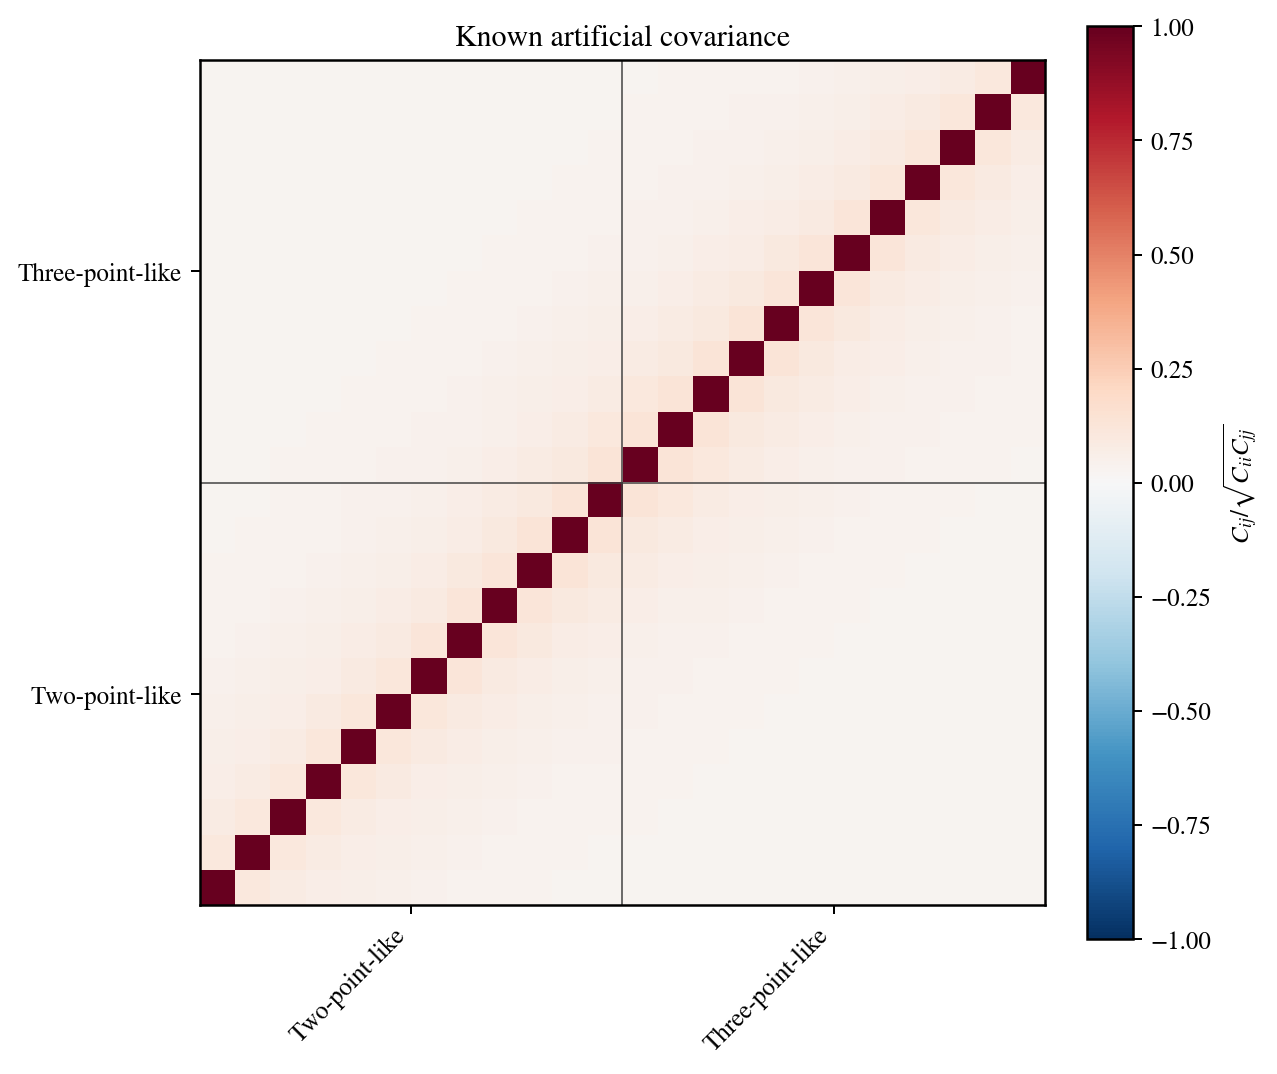

In [10]:
# Use an artificial joint vector whose true covariance is known exactly.
# The first 12 rows mimic two-point measurements and the last 12 mimic
# three-point measurements. Their scales differ, and their cross block is
# nonzero, so the exercise tests the full joint weighting.
# Eighteen training vectors cannot give an invertible 24-row sample
# covariance: after fitting the mean its rank is at most 17.
# PME can still run because it inverts the analytic model, not that sample.
report = controlled_precision_study(
    # Total number of entries in each measured vector.
    ndata=24,
    # Independent draws used to estimate the covariance correction.
    training_count=18,
    # Separate cheap Gaussian draws; these are not additional DES skies.
    validation_count=1200,
    # Fix the teaching experiment so its printed results are reproducible.
    seed=1937,
)
print(report["system"]["scope"])
print("Training vectors:", report["training_count"])
print("Rows:", report["system"]["truth"].shape[0])
print("Full sample rank:", report["sample_rank_in_model_units"])
print("Attempted sample inverse:", report["sample_inverse_attempted"])
print("Separate streams:", report["training_stream"],
      report["validation_stream"])
# Divide covariance entries by their two standard deviations for this plot.
# This displays correlations without hiding the small-unit third-order block.
plots.plot_correlation(
    covariance=report["system"]["truth"],
    labels=["Known artificial covariance", "Reference"],
    block_sizes=[12, 12],
    block_labels=["Two-point-like", "Three-point-like"],
)

### 7.1 Separate truncation error from simulation noise

The small example derived the series in Section 6. Here the controlled
experiment knows the true covariance, so it can evaluate the true residual
matrix and its largest absolute eigenvalue, denoted $\rho$.

When $\rho<1$, the operator-norm remainder after second order is bounded by

$$\frac{\rho^3}{1-\rho}.$$

This is a bound in dimensionless model coordinates. It is not a bound on
every dimensional covariance entry or marginalized parameter error.

The output distinguishes this true truncation error from the error of a
noisy correction. A radius estimated from simulations cannot prove the
unknown true series converges. The exact polynomial is positive for a
symmetric true residual, but its bias-corrected noisy estimate can have
negative eigenvalues. That difference is part of what we test below.

In [11]:
# In this teaching experiment only, we know the true covariance. We can
# therefore distinguish an error in the analytic model from the random
# error caused by estimating that covariance with 18 training vectors.
# The spectral radius is the largest absolute eigenvalue of the whitened
# model error. If the TRUE radius is below one, its inverse series converges.
# The noisy estimated radius is a different quantity; a singular sample
# already has residual eigenvalues of -1 even when the true model is good.
print("True residual spectral radius:",
      report["true_residual_spectral_radius"])
print("Model-unit remainder bound:",
      report["true_second_order_operator_error_bound"])
print("Exact second-order relative precision error:",
      report["diagnostics"]["exact_second_order"]
      ["relative_precision_frobenius_error"])
print("Estimated radii and positivity diagnostics:",
      report["estimator_diagnostics"])

True residual spectral radius: 0.13411494708014332
Model-unit remainder bound: 0.0027859370874408276
Exact second-order relative precision error: 0.0005025586134356025
Estimated radii and positivity diagnostics: {'component': {'estimated_residual_spectral_radius': 0.4024162430184342, 'minimum_polynomial_eigenvalue': 0.653755481036972, 'independent_count': 18, 'order': 2, 'sample_scope': 'separately_simulated_B_covariance'}, 'full': {'estimated_residual_spectral_radius': 2.9396507416907482, 'minimum_polynomial_eigenvalue': -1.9247899444826453, 'independent_count': 18, 'order': 2}}


### 7.2 Correct only a separately simulated component

When simulations genuinely isolate the contribution $B$, whiten its sample:

$$S_B=L^{-1}\widehat B L^{-\mathsf T}.$$

Whiten the independently fixed model for that component too:

$$T=L^{-1}B_mL^{-\mathsf T}.$$

The residual is now the difference between the true whitened component and
$T$. Its squared expansion contains two multiplication orders. Replacing
the unknown component by its sample gives the corrected polynomial

$$\widehat P_{2,B}=I-S_B+T+Q_B-S_BT-TS_B+T^2.$$

Compute $Q_B$ with exactly the operations in Section 5, using $S_B$ in place
of $S$. Keep both cross products; matrices generally do not commute. Restore
units with the same Cholesky factors as in Section 6.

A sample of the **full** vector cannot be used here by subtracting a known
$A$: that difference is not a Wishart sample of $B$. Conversely, adding a
fixed $A$ to a Wishart sample of $B$ does not make a full Wishart covariance.
The controlled experiment below knows which random contribution it drew.
The real shear measurement needs a physically justified decomposition.

**A small check of the two multiplication orders.** Use an identity model
covariance and these two whitened component matrices:

$$S_B=\begin{pmatrix}0.4&0.1\\0.1&0.2\end{pmatrix}.$$

The independently specified component model is

$$T=\begin{pmatrix}0.3&0\\0&0.1\end{pmatrix}.$$

The known covariance contribution is therefore the diagonal matrix with
entries 0.7 and 0.9. In the code, compare the off-diagonal entries of
`S_B @ T` and `T @ S_B`. Each product is asymmetric, but their sum is
symmetric. Dropping one order would change the estimated precision.

In [12]:
# This example supposes ten independent Gaussian B-only vectors.
# It does not obtain B by subtracting a fixed noise term from full vectors.
component_sample = np.array([[0.4, 0.1], [0.1, 0.2]])
component_model = np.diag(v=[0.3, 0.1])
component_nu = 10 - 1
component_square = component_sample @ component_sample
component_trace = np.trace(a=component_sample)
component_q = component_nu**2 * component_square
component_q -= component_nu * component_trace * component_sample
component_q /= component_nu**2 + component_nu - 2.
first_product = component_sample @ component_model
second_product = component_model @ component_sample
component_polynomial = np.eye(N=2) - component_sample + component_model
component_polynomial += component_q
component_polynomial -= first_product
component_polynomial -= second_product
component_polynomial += component_model @ component_model
print("S_B times T:\n", first_product)
print("T times S_B:\n", second_product)
print("Corrected component precision (M is identity):\n", component_polynomial)
component_shared, component_diagnostics = component_precision_expansion(
    analytic=np.eye(N=2),
    component_model=component_model,
    component_sample=component_sample,
    independent_count=10,
    order=2,
)
np.testing.assert_allclose(component_shared, component_polynomial, rtol=1.e-13)

S_B times T:
 [[0.12 0.01]
 [0.03 0.02]]
T times S_B:
 [[0.12 0.03]
 [0.01 0.02]]
Corrected component precision (M is identity):
 [[ 0.88193182 -0.09090909]
 [-0.09090909  0.90375   ]]


### 7.3 A product from independent groups

When Gaussian sampling moments are doubtful, two independent covariance
groups can supply the square instead. Whiten both, obtaining $S_1$ and
$S_2$. Their symmetric cross product is

$$Q_\mathrm{split}=\frac{S_1S_2+S_2S_1}{2}.$$

Independence makes its expectation equal to the true square. Use their
average in the linear term:

$$\widehat P_{2,\mathrm{split}}=3I-3\frac{S_1+S_2}{2}+Q_\mathrm{split}.$$

This product identity needs independence and unbiased covariances, but not
Gaussian vectors. Splitting a finite budget makes each covariance noisier;
it does not cure truncation error. In the controlled experiment each group
supplies a known $A$ plus an independently estimated $B$. No validation
realization enters either training group.

The next cell defines `plot_precision_errors`, the figure of this section:
one sorted-eigenvalue error line per estimator, read from the
`controlled_precision_study` report.

In [13]:
# Functions of this notebook: the precision-error figure of section 7.3.
import importlib

import numpy as np


def plot_precision_errors(report):
    """Draw dimensionless precision errors, including failed estimates.

    The figure of section 7.3: one line per estimator of the controlled
    experiment, each the sorted eigenvalues of Lc.T Psi Lc - I computed
    by precision_diagnostics (zero everywhere would be a perfect
    estimate). Failed, indefinite estimates stay in the figure instead
    of being repaired, so the reader sees the failure.

    Arguments:
      report = controlled_precision_study result.
    Returns:
      Shared figure/axes. Each line sorts the eigenvalues of Lc.T Psi Lc-I;
      sorted positions are not identifications of shared physical eigenvectors.
    """
    # The plotting module is named cosmolike_notebook_utils.3pcf: a module
    # name starting with a digit cannot appear in an import statement, so
    # importlib.import_module loads it from its name as text.
    plots = importlib.import_module(name="cosmolike_notebook_utils.3pcf")
    names = (
        "analytic",
        "component_wishart",
        "component_split",
        "full_wishart",
    )
    labels = [
        "Analytic model",
        "Known A + Wishart B",
        "Known A + independent B groups",
        "Full-covariance Wishart",
    ]
    curves = []
    coordinate = np.arange(report["system"]["truth"].shape[0]) + 1
    for name in names:
        errors = report["diagnostics"][name]["precision_error_eigenvalues"]
        curves.append((coordinate, errors[None, :]))
    return plots.plot_ia_components(
        components=curves, component_labels=["Precision error"],
        coordinate_label="Sorted eigenvalue index",
        quantity_label=r"Eigenvalues of $L_C^{\mathsf{T}}\hat{\Psi} L_C-I$",
        legend=labels, xscale="linear", ncols=1, figsize=(10, 5),
        bintextpos=None, colorbar=None, show=None,
    )

truth positive_precision relative precision error = 2.7076603902301054e-16
analytic positive_precision relative precision error = 0.03604560126458969
exact_second_order positive_precision relative precision error = 0.0005025586134356025
component_wishart positive_precision relative precision error = 0.19056457595048829
full_wishart refused_nonpositive_precision relative precision error = 1.922485575393032
component_split positive_precision relative precision error = 0.20388279594938835


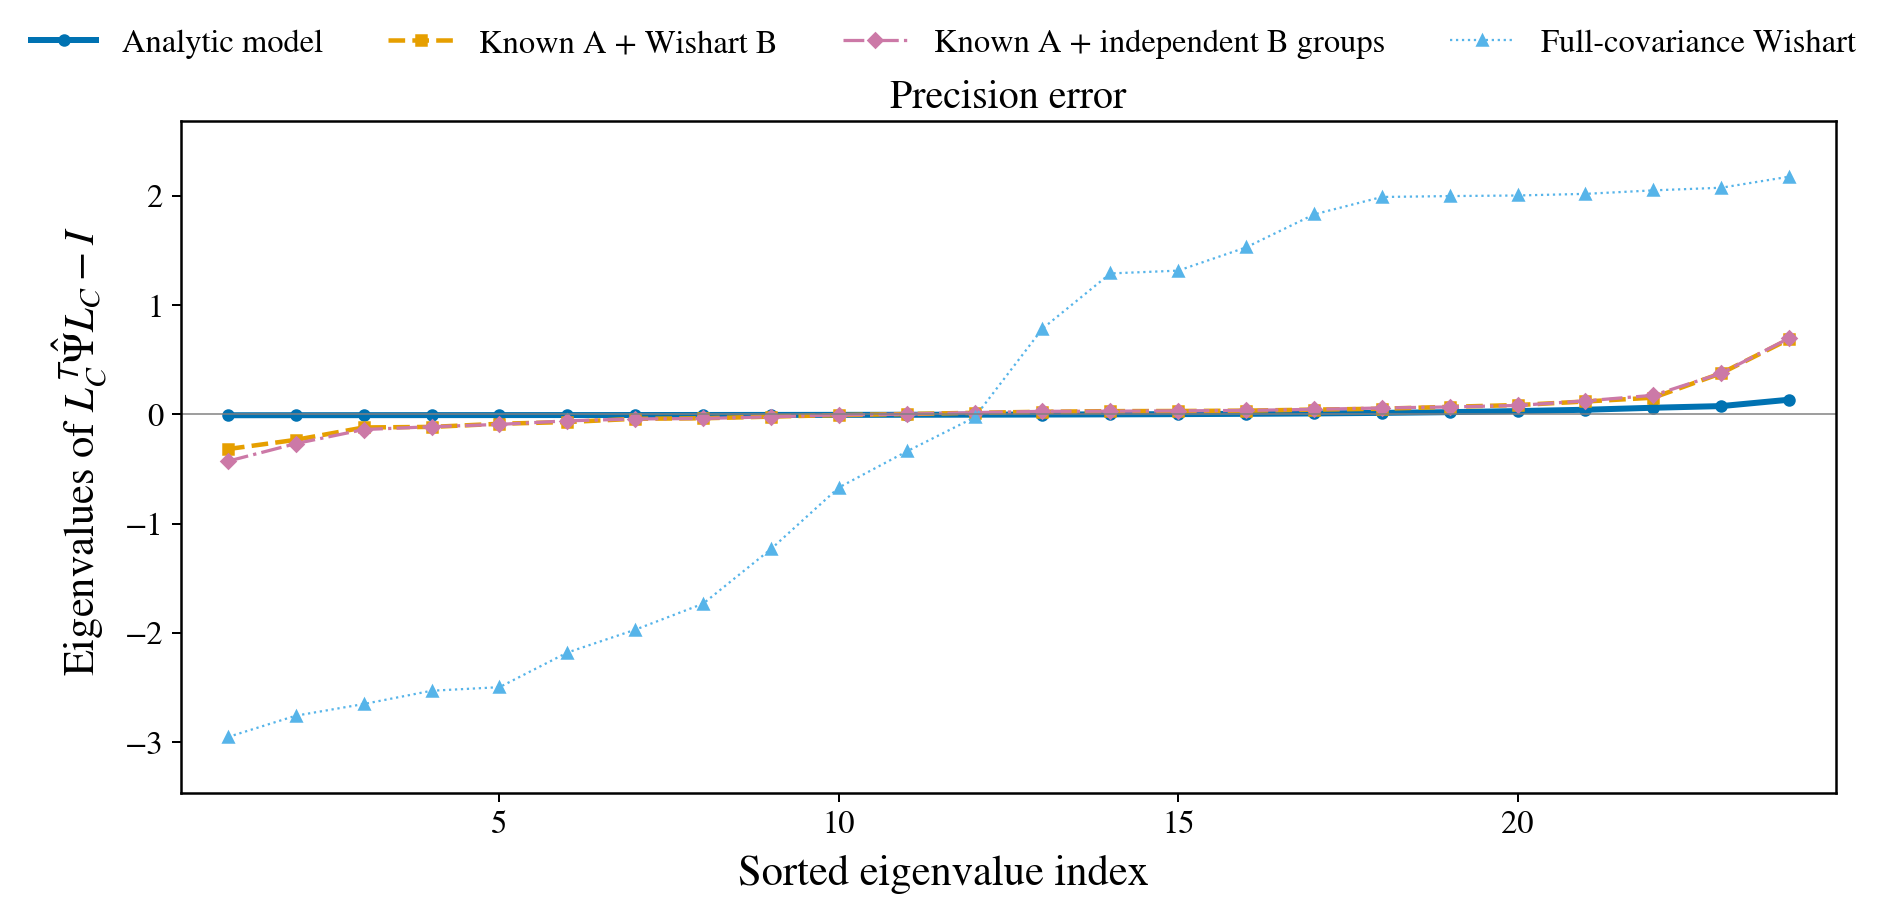

In [14]:
# Compare the analytic model, exact truncated expansion and simulation
# estimates. The exact truncated result isolates the error from omitting
# higher powers; the estimated results also contain finite-sample noise.
# A reported nonpositive precision cannot weight a Gaussian likelihood.
# The plot keeps such failures visible instead of repairing eigenvalues.
for method, diagnostics in report["diagnostics"].items():
    print(method, diagnostics["inference_status"],
          "relative precision error =",
          diagnostics["relative_precision_frobenius_error"])
precision_figure, precision_axes = plot_precision_errors(report=report)
plt.show()

Each line above sorts the eigenvalues of $L_C^{\mathsf T}\widehat\Psi L_C-I$,
where $C=L_CL_C^{\mathsf T}$ factorizes the known true covariance. Zero means
exact precision in that direction, and sorting does not identify a shared
physical eigenvector across methods. An eigenvalue at or below $-1$ marks a
nonpositive precision direction and prohibits using that estimate as a
Gaussian likelihood; the code keeps such a failure in the diagnostic plot,
refuses its parameter errors, and never clips eigenvalues.

One realization need not rank the estimators by their average performance. The
known-component method reduces the source of sampling noise in this
experiment, and its benefit depends on the covariance decomposition and the
quality of the analytic model; the source tests separately compare a small
Gaussian ensemble with the expected truncated series.

In this realization, the analytic model is closer to the true precision than
either noisy correction. Estimating only $B$ reduces the error substantially
relative to estimating the whole covariance, but eighteen training
realizations do not make a correction beneficial relative to this good
analytic starting model; more simulations and independent validation must
decide whether to apply one. The random draw stays as drawn.

## 8. Test the error bars, not only the matrix entries

The controlled model's mean responds linearly to three artificial parameters:

$$\mu=D\boldsymbol p.$$

The columns of $D$ are prescribed responses named amplitude, alignment and
shape. These are teaching labels, not measured DES derivatives. With a
positive precision estimate, the fit's Fisher matrix is

$$F=D^{\mathsf T}\widehat\Psi D.$$

The operation that turns a data vector into a fitted parameter vector is

$$H=F^{-1}D^{\mathsf T}\widehat\Psi.$$

Applying it to one realization gives

$$\widehat{\boldsymbol p}=Hd.$$

The fit quotes parameter covariance $F^{-1}$. Its actual repeated-experiment
covariance instead follows by propagating the true data covariance:

$$C_{p,\mathrm{actual}}=HCH^{\mathsf T}.$$

These agree for the true precision, but can differ when an approximate
precision gives the wrong weights. The plots compare quoted errors with the
known truth and with 1,200 independent validation draws. This validates one
estimated precision realization. A coverage study must also repeat the
training experiment.

The next cell defines `plot_precision_parameter_errors`, which draws the
quoted error of each artificial parameter, divided by the true one, for
every estimator whose precision estimate is positive definite. The run
cell after it also prints the validation variance ratios.

In [15]:
# Functions of this notebook: the parameter-error figure of section 8.
import importlib


def plot_precision_parameter_errors(report):
    """Plot quoted parameter errors only for positive precision estimates.

    The figure of section 8: for every estimator whose precision
    estimate is positive definite, the quoted error sigma of each
    artificial parameter divided by the true sigma. An indefinite
    estimate cannot weight a Gaussian likelihood, so it is reported in
    text instead of drawn. A positive precision alone does not
    establish coverage; the validation variance ratios of the report
    are the separate check of the quoted errors.

    Arguments:
      report = controlled_precision_study result with known true precision.
    Returns:
      Shared figure/axis showing sigma/sigma_true.
    """
    # importlib.import_module loads the digit-led module name (see
    # plot_precision_errors).
    plots = importlib.import_module(name="cosmolike_notebook_utils.3pcf")
    errors = []
    labels = []
    methods = (
        ("analytic", "Analytic model"),
        ("component_wishart", "Known A + Wishart B"),
        ("component_split", "Known A + independent B groups"),
        ("full_wishart", "Full-covariance Wishart"),
    )
    for name, label in methods:
        diagnostics = report["diagnostics"][name]
        if diagnostics["positive"]:
            errors.append(diagnostics["sigma"])
            labels.append(label)
        else:
            print(f"No parameter contour for {label}: nonpositive precision.")
    return plots.plot_parameter_errors(
        names=report["system"]["parameter_names"], errors=errors,
        errors_ref=report["diagnostics"]["truth"]["sigma"],
        legend=labels, figsize=(11, 5), show=None,
    )

No parameter contour for Full-covariance Wishart: nonpositive precision.


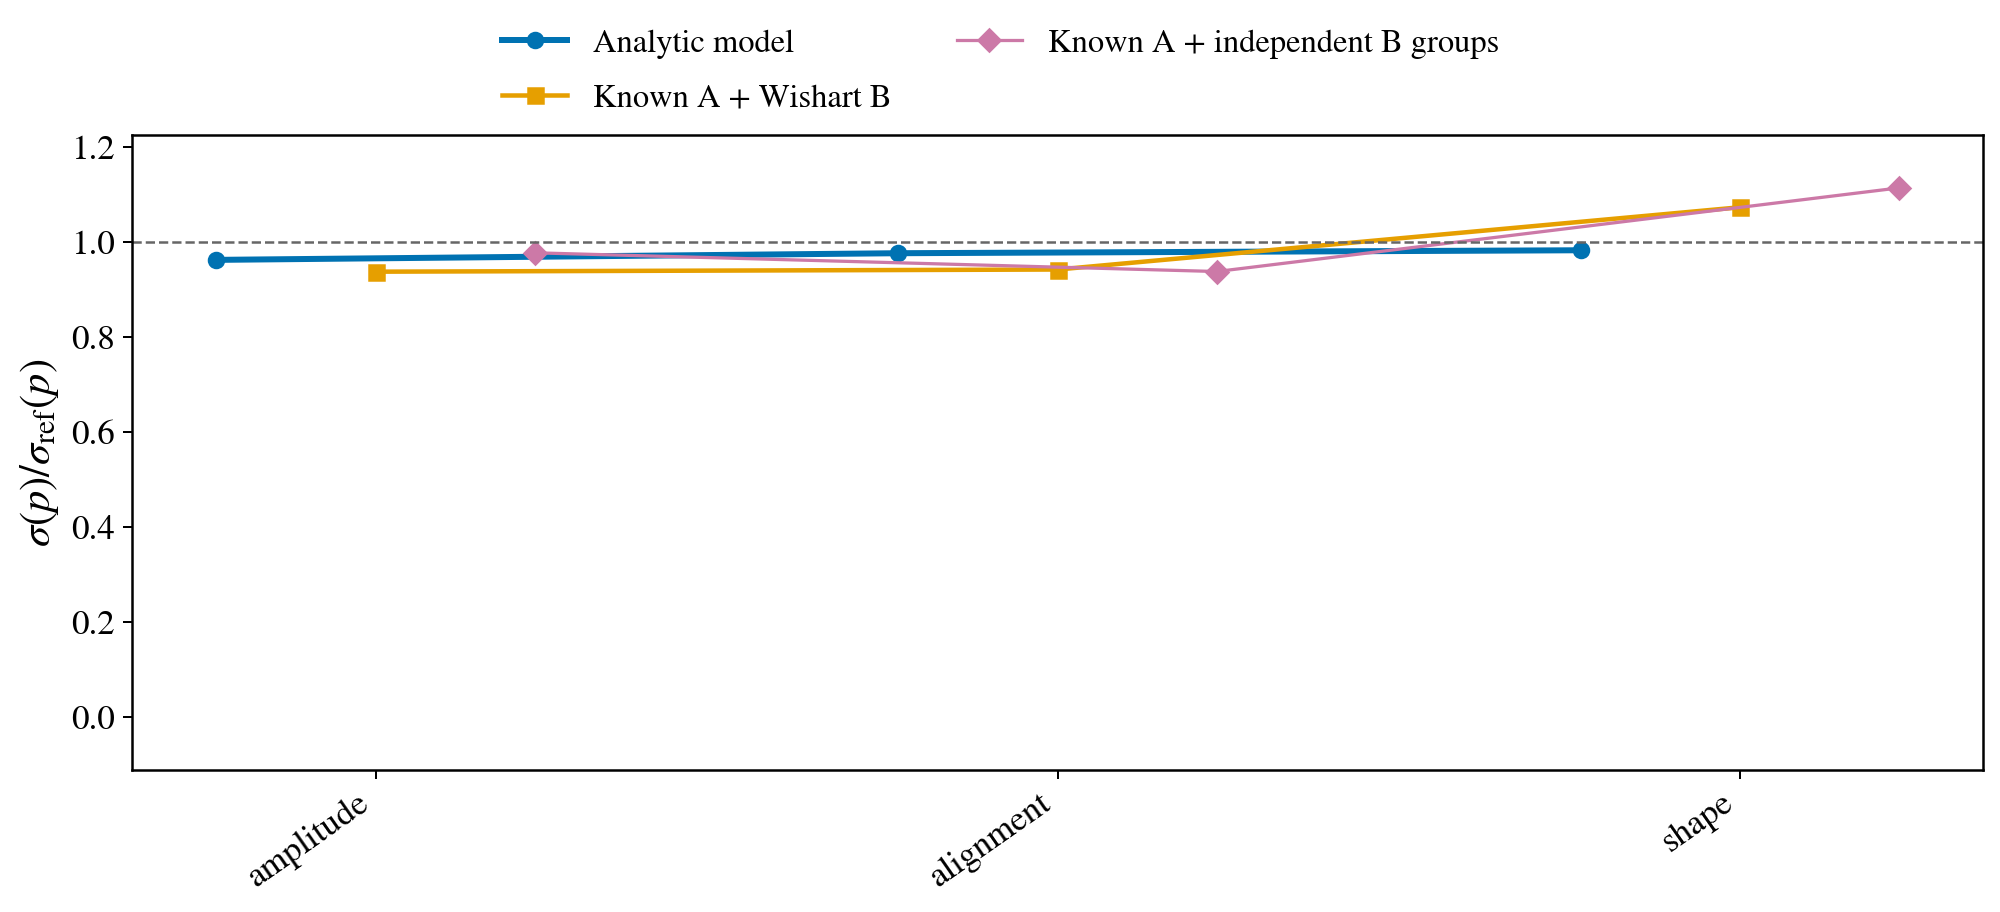

truth
Exact variance / quoted variance: [1. 1. 1.]
Validation variance / quoted variance: [0.9353738  0.9920423  1.01861395]
Validation mean quadratic / row count: 0.9846148847820811
analytic
Exact variance / quoted variance: [1.08189129 1.0510291  1.03793727]
Validation variance / quoted variance: [1.01362679 1.04248163 1.05817678]
Validation mean quadratic / row count: 0.9976727956573369
exact_second_order
Exact variance / quoted variance: [1.00121846 1.00021978 1.00011629]
Validation variance / quoted variance: [0.93652051 0.99225723 1.01873673]
Validation mean quadratic / row count: 0.984744958853503
component_wishart
Exact variance / quoted variance: [1.16523076 1.15038435 0.90063282]
Validation variance / quoted variance: [1.06835777 1.14474793 0.90662449]
Validation mean quadratic / row count: 1.0093599257713866
full_wishart is excluded from parameter inference.
component_split
Exact variance / quoted variance: [1.09929729 1.16097989 0.85663332]
Validation variance / quoted vari

In [16]:
# A good covariance is useful only if it gives reliable parameter errors.
# The teaching model has prescribed derivative columns, so we can compare
# the scatter expected under the known true covariance with the error bars
# that each approximate precision would quote.
# The independent validation vectors provide a second, empirical check.
parameter_figure, parameter_axis = plot_precision_parameter_errors(
    report=report,
)
plt.show()
# A variance ratio of one means the quoted variance matches the scatter.
# Greater than one means the quoted error bar is too small. The validation
# ratio fluctuates because it is estimated from a finite independent sample.
for method, diagnostics in report["diagnostics"].items():
    if diagnostics["positive"]:
        print(method)
        print("Exact variance / quoted variance:",
              diagnostics["exact_variance_over_quoted"])
        print("Validation variance / quoted variance:",
              diagnostics["validation_variance_over_quoted"])
        # This last diagnostic checks the whole data-vector weighting, rather
        # than only the selected parameter directions. The model mean is
        # known here; fitting a mean would change the reference expectation.
        print("Validation mean quadratic / row count:",
              diagnostics["validation_mean_quadratic_per_row"])
    else:
        print(method, "is excluded from parameter inference.")

## 9. Replace the controlled vectors with real joint realizations

A real archive must contain `vectors[N,p]`, ordered `row_labels[p]`,
`row_kind[p]`, `parent_ids[N]`, and the scalar string `estimator`. The loader
checks the row labels, row kinds and the estimator string, and it never
reorders columns. Those checks are necessary, not sufficient: the name
`finite_sas`, the finite side-angle-side estimator, does not encode triangle
cuts, bin averages, weights, masks or source calibration. The analyst must
compare a recorded estimator and input manifest for the simulations and the
analytic calculation, including the joint cross-covariance and the source
ordering. `excluded_parent_ids` records skies that tuned the analytic model or
validated the result; the loader refuses overlap with training.

The simulations in hand today are Rafael Gomes' CosmoGrid DES Y3 shear maps
(NSIDE 512; the 15,997 downloaded map files are described in
`maps_cov_512_v2/README.md` and in section 10), and they do not satisfy this
contract. The public Y3 construction's 796 patches come from 199 parent
skies, so they are not 796 independent realizations merely because they
occupy separate rows in a file. The loader refuses repeated parent IDs, and it does not average
patches, because averaging would change the estimator and the covariance. The
analyst must construct a defensible independent realization set or derive a
correlated-realization correction; a file count alone justifies no Wishart
degree-of-freedom choice.

For a full joint simulation archive, the intended calls are:

```python
simulation = load_joint_simulations(
    path=PROJECT / "chains" / "independent_joint_vectors.npz",
    expected_labels=analytic_row_labels,
    expected_kind=analytic_row_kind,
    expected_estimator="finite_sas",
    excluded_parent_ids=validation_and_tuning_parents,
)
sample = covariance_of_vectors(vectors=simulation["vectors"])
precision, diagnostics = precision_expansion(
    analytic=analytic_covariance,
    sample=sample,
    independent_count=simulation["independent_count"],
    order=2,
)
```

These lines are a file contract, not a claim that such independent DES
realizations exist. The component version also needs simulations whose
covariance really is $B$ and a validated independent $A$; the demonstrated PME
is also not a Hartlap rescaling, a multivariate-t likelihood, or a correction
for errors in the mean model.

The compiled covariance covers the full-filter gravitational model and its
chosen terms; it is not a converged, estimator-matched finite-SAS TATT
covariance for this DES example. This notebook teaches the correction method
and leaves that physical covariance and the missing independent survey
realizations as separate work.

In [17]:
# Functions of this notebook: the reader of real joint realizations (section 9).
# It is the file contract section 9 describes; no notebook cell calls it
# yet, because no archive of independent realizations exists.
from pathlib import Path

import numpy as np


def load_joint_simulations(path, expected_labels, expected_kind,
                           expected_estimator, excluded_parent_ids=()):
    """Read an archive of independent joint DES Y3 realizations (section 9).

    This is the file contract of section 9: the loader that a future
    archive of independent joint realizations must pass before its
    sample covariance can feed the precision correction. No notebook
    cell calls it yet, because no archive satisfying the contract
    exists. The simulations in hand today are Rafael Gomes' CosmoGrid
    DES Y3 shear maps (NSIDE 512, 15,997 downloaded map files;
    maps_cov_512_v2/README.md and Gomes et al., arXiv:2503.03964), and
    they do not satisfy it: the public Y3 construction's 796 patches
    are cut from only 199 parent full-sky realizations, so patches
    sharing a parent sky are correlated (section 10).

    One vector is one complete joint measurement (all xi and Map3 rows)
    on one simulated patch. A parent ID names the full-sky realization
    a patch was cut from; each must occur exactly once, because the
    sample covariance and the Wishart correction count independent
    draws. Patches sharing a parent are refused rather than averaged,
    because averaging would change the estimator and its covariance.
    Unique IDs alone do not prove independence — that is a scientific
    input declaration, and the caller must establish how the
    realizations were built (notes/covariance_from_simulations/ and
    notes/covariance_comparison/ discuss the counting). Parents used to
    tune or validate the analytic model are excluded through
    excluded_parent_ids.

    The NPZ must contain vectors[N,p], row_labels[p], row_kind[p],
    parent_ids[N], and the scalar string estimator.

    Arguments:
      path = an explicit NPZ file, read with allow_pickle=False.
      expected_labels, expected_kind = exact ordered row identities of the
          analytic covariance; each group must contain xi and Map3 rows.
      expected_estimator = declared estimator string. finite_sas names
          the finite side-angle-side estimator the likelihood uses
          (Map3 assembled from the shear three-point function on finite
          side and opening-angle bins); the compiled covariance's other
          convention is full_filter, the all-triangle aperture moment.
          A family name does not verify triangle cuts, weights, masks
          or source calibration; compare the input/measurement
          manifests separately before interpreting a survey correction.
      excluded_parent_ids = parents used for analytic tuning or validation;
          any overlap is refused before a sample covariance is formed.
    Returns:
      Owned vectors, labels, kinds, parent IDs and independent count.
    Raises:
      ValueError for shape, finite-value, row-order, estimator or parent
      errors.
    """
    # ----------------------------------------------------------------------
    # Read the required arrays; a missing name fails before anything is
    # interpreted. The copies detach the results from the open archive.
    # ----------------------------------------------------------------------
    filename = Path(path)
    required = (
        "vectors",
        "row_labels",
        "row_kind",
        "parent_ids",
        "estimator",
    )
    arrays = {}
    with np.load(filename, allow_pickle=False) as archive:
        for name in required:
            if name not in archive.files:
                raise ValueError(f"Simulation archive lacks {name}.")
            arrays[name] = archive[name].copy()

    # ----------------------------------------------------------------------
    # Vector and row checks: finite numeric vectors, row labels and kinds
    # matching the analytic covariance exactly, and both row groups
    # present.
    # ----------------------------------------------------------------------
    vectors = arrays["vectors"]
    if (vectors.dtype.kind not in "fiu" or vectors.ndim != 2
            or vectors.shape[0] < 3
            or not np.all(np.isfinite(vectors))):
        raise ValueError("Need finite independent vectors[N,p] with N>2.")
    labels = arrays["row_labels"]
    kinds = arrays["row_kind"]
    parents = arrays["parent_ids"]
    if (labels.shape != (vectors.shape[1],)
            or kinds.shape != labels.shape
            or parents.shape != (vectors.shape[0],)):
        raise ValueError("Simulation rows or parent IDs have wrong shapes.")
    if (not np.array_equal(labels, expected_labels)
            or not np.array_equal(kinds, expected_kind)):
        raise ValueError("Simulation rows do not match the analytic matrix.")
    if (np.unique(labels).size != labels.size
            or np.any(~np.isin(kinds, ("xip", "xim", "map3")))
            or not np.any(kinds == "map3")
            or not np.any(kinds != "map3")):
        raise ValueError("Require unique labeled joint xi and Map3 rows.")

    # ----------------------------------------------------------------------
    # Estimator and parent checks: one declared estimator string matching
    # the analytic side, and parent IDs that are nonempty, unique and
    # disjoint from the tuning/validation parents.
    # ----------------------------------------------------------------------
    if arrays["estimator"].shape != ():
        raise ValueError("Simulation estimator must be one declared string.")
    if str(arrays["estimator"].item()) != expected_estimator:
        raise ValueError("Simulation and analytic estimators differ.")
    if parents.dtype.kind not in "iuUS":
        raise ValueError("Parent IDs must be integer or text identifiers.")
    if parents.dtype.kind in "US" and np.any(parents == ""):
        raise ValueError("Parent IDs must not be empty text identifiers.")
    if np.unique(parents).size != parents.size:
        raise ValueError(
            "Repeated parent IDs: patches are not independent skies."
        )
    if np.intersect1d(parents, np.asarray(excluded_parent_ids)).size:
        raise ValueError("Training parents overlap tuning or validation.")

    return {
        "vectors": vectors.copy(),
        "row_labels": labels.copy(),
        "row_kind": kinds.copy(),
        "parent_ids": parents.copy(),
        "independent_count": int(vectors.shape[0]),
        "estimator": expected_estimator,
    }

## 10. What Rafael's downloaded maps contain

**Rafael confirmed:** these are CosmoGrid shear maps at NSIDE 512. Only
pixels with nonzero DES footprint are stored; `indices_512.npy` identifies them.
The [folder guide](maps_cov_512_v2/README.md) and
[viewing notebook](maps_cov_512_v2/EXAMPLE_VIEW_MAPS.ipynb) explain how to
recover and display the footprint. The index file has 369,190 unique integer entries matching the map axis.
The viewing notebook compares both orderings: RING recovers the DES footprint;
NESTED does not. This is geometric evidence, not producer confirmation of
the shear-component signs or basis.

Only `run_0000_ncut0_nreal0` and `run_0000_ncut0_nreal1` were inspected.
Both arrays have shape `(4, 2, 369190)` and dtype `float64`. A bounded sample
of their first 4,096 pixels in each slot was finite. Four source bins and
two components are consistent with the shape, but their ordering and signs
must be confirmed. Do not reshape the last axis into an image: position
`j` refers to sky pixel `indices[j]`.

There are three different objects here:

| Object | What one row or entry means | Used for |
|---|---|---|
| Shear map | A component at one retained sky pixel | Measuring correlations |
| Joint vector | One xi or aperture statistic in a specified bin | Estimating a covariance |
| Parent simulation | One independently generated density realization | Counting cosmic-variance information |

The file labels suggest `run` is the parent, `ncut` a footprint and `nreal`
a noise realization. This interpretation is **not confirmed** by the pixel
message. Keep provisional groups intact until the producer specifies their
meaning. A new file does not by itself increase the independent sky count.
The directory is ignored by Git except for its guide and viewing notebook.

## 11. Restore the noise of one survey after averaging repeated draws

Suppose different `nreal` labels mean conditionally independent noise draws
of one parent sky and one fixed footprint. Define $B$ as the covariance
across skies of their conditional mean measurement. Define $A$ as the
within-sky noise covariance, averaged over skies. One observed survey has

$$C=B+A.$$

Averaging $K$ measured vectors of one parent reduces its noise by $K$.
Therefore the covariance of those parent means has expectation

$$\mathbb E[\widehat C_{\bar d}]=B+\frac{A}{K}.$$

The average within-parent sample covariance, $\widehat A$, estimates $A$.
Subtract its contribution to the parent means to estimate $B$:

$$\widehat B=\widehat C_{\bar d}-\frac{\widehat A}{K}.$$

To recover the covariance of **one** noisy survey, add back one full copy of
the noise term:

$$\widehat C=\widehat B+\widehat A.$$

Inserting the previous expression gives the computable form

$$\widehat C=\widehat C_{\bar d}+\left(1-\frac1K\right)\widehat A.$$

The following scalar calculation mirrors the notes. It uses exact expected
values, so it isolates the missing-noise effect from finite-sample scatter.

In [18]:
# Sky-to-sky variance is 4; the noise of one survey contributes another 9.
# Twenty redraws reduce the noise of a parent mean to 9/20, not to zero.
noise_draws = 20
sky_variance = 4.
noise_variance = 9.
parent_mean_variance = sky_variance + noise_variance / noise_draws
estimated_sky_variance = parent_mean_variance - noise_variance / noise_draws
restored_survey_variance = estimated_sky_variance + noise_variance
print("Variance of parent means:", parent_mean_variance)
print("After subtracting their residual noise:", estimated_sky_variance)
print("After restoring one survey's noise:", restored_survey_variance)
np.testing.assert_allclose(restored_survey_variance, 13.)

Variance of parent means: 4.45
After subtracting their residual noise: 4.0
After restoring one survey's noise: 13.0


This calculation requires equal $K$, the same measurement and footprint,
independent parents, and independent noise draws conditional on each parent.
Different cuts of one sky remain grouped with that sky. Averaging maps before
measuring a nonlinear statistic does not perform this calculation: average
the **measured vectors** instead.

The difference defining $\widehat B$ is not a Wishart sample covariance.
Do not pass it to the component correction with the number of files as its
degrees of freedom. The repeated-draw identity can improve covariance
estimation while still needing a separate treatment of noisy matrix products.

## 12. A small first experiment, followed by a real validation

First confirm the parent/noise labels, coordinates, ordering, shear basis,
source distributions and weights. Select a small, explicit set of complete
files. Measure both xi and Map3 on each of the **same** selected maps;
concatenate their rows before forming the sample covariance. Estimating
the two diagonal blocks separately would discard the cross-covariance we
need to assess the benefit of combining them.

As an initial independent-sky construction, use one preselected cut and one
preselected noise realization per independent parent. This discards some
repeats but makes the sample definition testable. Split at the parent level
into training and validation; reserve separate parents if tuning the
analytic model. More cuts per sky require a study of their correlations,
not a larger integer passed to PME.

[Rafael's methods paper](https://arxiv.org/html/2503.03964v2#S3) describes
NSIDE 1024 maps. The supplied maps have NSIDE 512, with a pixel scale about
6.87 arcminutes rather than 3.44. The paper's small-triangle cuts and pixel
treatment cannot simply be reused. Test resolution, angular cuts and bin
weights with matched analytic predictions before making a DES claim. Where
higher-resolution counterparts are unavailable, retain this as an unresolved
systematic rather than calling the coarse-map result converged.

For measured vectors in `chains/`, the full-covariance call in Section 6 is
the first available route. First order avoids estimating a squared sample
covariance; second order uses a Gaussian/Wishart assumption. Joint aperture
vectors need not be Gaussian. As a further diagnostic, two disjoint parent
groups can supply `split_precision_expansion`: independence makes their
cross-product unbiased for the covariance square without Gaussianity.
It still has sampling variance and truncation error; hold out a third group
for validation. These are future measured-vector calculations, not jobs
started by opening this notebook.

Compare the analytic precision and the corrected precision with identical
mean models, derivatives, priors and data rows. Check positive definiteness,
parameter-error changes, and recovery on held-out mocks. A smaller ellipse
alone is not success: its claimed coverage must agree with the scatter of
recovered parameters. No eigenvalue clipping or Hartlap factor should be
added to hide a failed PME estimate. The notes explain the distinction
between a noisy residual diagnostic and the true convergence condition.

The executed [map experiment](EXAMPLE_COVARIANCE_MAPS.ipynb) now applies
this workflow to coarse aperture moments from Rafael's files. Its Gaussian
reference is calibrated on separate maps, and its first small correction
fails the positivity check. Read its measurement definition and assumptions
before interpreting those results as evidence about the DES likelihood.

## 13. From second order to fourth order: do each multiplication

Here the true covariance $C$ and the starting model $M$ are fixed. Define
its Cholesky factor before changing coordinates:

$$M=LL^{\mathsf T}.$$

The true covariance in model units is

$$R=L^{-1}CL^{-\mathsf T}.$$

The residual is

$$X=R-I.$$

The sample covariance will enter only after we have derived the target.

### First multiply out the square.
The identity matrix leaves every matrix unchanged on either side. In
particular, the products used below obey
$$
 RI=IR=R,\qquad I^2=I.
$$
We need this property because two arbitrary matrices cannot be reordered.
Start by replacing each residual factor by its definition:
$$
 X^2=(R-I)(R-I).
$$
The first term in the left bracket multiplies both terms on the right;
then the second term does the same. This gives four products:
$$
 X^2=RR-RI-IR+II.
$$
Use the identity rules above, without changing any other product order:
$$
 X^2=R^2-R-R+I=R^2-2R+I.
$$
Now insert the residual and its square into the second-order polynomial:
$$
 P_2=I-(R-I)+(R^2-2R+I).
$$
The minus sign before the first bracket changes both signs in that bracket:
$$
 P_2=I-R+I+R^2-2R+I.
$$
Keep the identity, linear and quadratic terms in separate groups:
$$
 P_2=(1+1+1)I+(-1-2)R+R^2.
$$
Adding the scalar coefficients gives the familiar starting point:
$$
 P_2=3I-3R+R^2.
$$

### Multiply once more to obtain the cubic residual.
Instead of quoting a binomial formula, multiply the square we just found
by one more copy of the residual:
$$
 X^3=(R^2-2R+I)(R-I).
$$
First multiply the left bracket by $R$, retaining all three terms:
$$
 (R^2-2R+I)R=R^3-2R^2+R.
$$
Then multiply the same bracket by $-I$:
$$
 (R^2-2R+I)(-I)=-R^2+2R-I.
$$
Add those two results before collecting coefficients:
$$
 X^3=R^3-2R^2+R-R^2+2R-I.
$$
There is one cubic term, two quadratic contributions and two linear
contributions. Grouping them explicitly gives
$$
 X^3=R^3+(-2-1)R^2+(1+2)R-I.
$$
Thus the cube needed by the inverse series is
$$
 X^3=R^3-3R^2+3R-I.
$$

### Subtract the whole cubic, including every sign.
Third order extends the second-order polynomial by $-X^3$:
$$
 P_3=P_2-X^3.
$$
Substitute both complete expressions, with brackets still visible:
$$
 P_3=(3I-3R+R^2)-(R^3-3R^2+3R-I).
$$
The minus sign changes all four terms of the second bracket, not only
the leading cubic term:
$$
 P_3=3I-3R+R^2-R^3+3R^2-3R+I.
$$
There are now two contributions to each of the identity, linear and
quadratic coefficients:
$$
 P_3=(3+1)I+(-3-3)R+(1+3)R^2-R^3.
$$
Adding them yields
$$
 P_3=4I-6R+4R^2-R^3.
$$
No sample covariance has entered. We are still calculating a polynomial
of the fixed, unknown true covariance in model units.

### Multiply again to obtain the quartic residual.
The fourth power is the cubic residual times one more residual:
$$
 X^4=(R^3-3R^2+3R-I)(R-I).
$$
Multiplication by the first term in the right bracket gives
$$
 (R^3-3R^2+3R-I)R=R^4-3R^3+3R^2-R.
$$
Multiplication by its second term gives
$$
 (R^3-3R^2+3R-I)(-I)=-R^3+3R^2-3R+I.
$$
Add these results, displaying which coefficients come from the two products:
$$
 X^4=R^4+(-3-1)R^3+(3+3)R^2+(-1-3)R+I.
$$
This reduces to
$$
 X^4=R^4-4R^3+6R^2-4R+I.
$$

### Add the quartic to the cubic approximation.
The geometric inverse series alternates signs in powers of $X$. Its
fourth term is positive, so this step is addition:
$$
 P_4=P_3+X^4.
$$
Substitute the expressions obtained above:
$$
 \begin{aligned}
 P_4={}&(4I-6R+4R^2-R^3)\\
       &+(R^4-4R^3+6R^2-4R+I).
 \end{aligned}
$$
Collect each power in its own coefficient, from the identity through the
fourth power:
$$
 P_4=(4+1)I+(-6-4)R+(4+6)R^2+(-1-4)R^3+R^4.
$$
The target polynomial is consequently
$$
 P_4=5I-10R+10R^2-5R^3+R^4.
$$
These integer coefficients follow from the multiplications and additions
just displayed. They are not fitted to simulation measurements.

### Check the signs with one number.
In one dimension set $R=1.2$, so $X=0.2$. The second-order value is
$$
 P_2=1-0.2+0.04=0.84.
$$
Subtract the cubic residual to obtain
$$
 P_3=0.84-0.008=0.832.
$$
Add the fourth power to obtain
$$
 P_4=0.832+0.0016=0.8336.
$$
The expression in powers of $R$ gives the same result independently:
$$
 P_4=5-12+14.4-8.64+2.0736=0.8336.
$$
The exact inverse is $1/1.2=0.83333\ldots$. This check illustrates the
finite truncation error; it is not a test of simulation noise.


### The next task is statistical

We need an unbiased estimate of each true power $R^j$. Taking powers of the
same observed covariance introduces repeated noise factors. The next cells
construct corrections for those products under Gaussian sampling, and then
an alternative based on products of distinct independent factors.
An unbiased estimate of $P_4$ targets this finite polynomial; it does not
have expectation exactly $R^{-1}$.


### 13.1 Recover the Gaussian matrix powers

Assume independent Gaussian vectors and their ordinary mean-subtracted
sample covariance. Then $\nu=N-1$. Let $t_j=\operatorname{tr}(S^j)$;
the trace sums diagonal entries after matrix multiplication. The second
power is the expression already derived:

$$Q_2=\frac{\nu^2S^2-\nu S t_1}{(\nu-1)(\nu+2)}.$$

For the cubic power, introduce its normalization first:

$$D_3=(\nu-2)(\nu-1)(\nu+2)(\nu+4).$$

The unbiased cubic is

$$Q_3=\frac{\nu^2}{D_3}
[\nu^2S^3-2\nu S^2t_1-\nu S t_2+2S t_1^2].$$

The fourth power contains seven matrix/trace terms. The code below keeps
them separate; the teaching notes derive their coefficients and display
them in a table. This is our extension of the paper's second-order
calculation, not a fourth-order formula quoted from the paper.
The exact check enumerates Gaussian pairings, solves the moment equations,
and also reduces the result to the scalar chi-square identity.

In [19]:
# This optional symbolic check needs SymPy, included in this Cocoa environment.
# It handles exact algebra only: no random vectors or map arrays are read.
import runpy
algebra = runpy.run_path(
    path_name=str(PROJECT / "notes" / "covariance_from_simulations"
                  / "derive_wishart_powers.py"),
)
algebra["verify"]()

DEGREE 2 exact matrix and scalar identities passed
  (2, ()) nu**2/((nu - 1)*(nu + 2))
  (1, (1,)) -nu/((nu - 1)*(nu + 2))
DEGREE 3 exact matrix and scalar identities passed
  (3, ()) nu**4/((nu - 2)*(nu - 1)*(nu + 2)*(nu + 4))
  (2, (1,)) -2*nu**3/((nu - 2)*(nu - 1)*(nu + 2)*(nu + 4))
  (1, (2,)) -nu**3/((nu - 2)*(nu - 1)*(nu + 2)*(nu + 4))
  (1, (1, 1)) 2*nu**2/((nu - 2)*(nu - 1)*(nu + 2)*(nu + 4))


DEGREE 4 exact matrix and scalar identities passed
  (4, ()) nu**5*(nu**2 + nu + 2)/((nu - 3)*(nu - 2)*(nu - 1)*(nu + 1)*(nu + 2)*(nu + 4)*(nu + 6))
  (3, (1,)) -3*nu**4*(nu**2 + nu + 2)/((nu - 3)*(nu - 2)*(nu - 1)*(nu + 1)*(nu + 2)*(nu + 4)*(nu + 6))
  (2, (2,)) -nu**4*(2*nu**2 + 3*nu - 6)/((nu - 3)*(nu - 2)*(nu - 1)*(nu + 1)*(nu + 2)*(nu + 4)*(nu + 6))
  (2, (1, 1)) nu**4*(5*nu + 6)/((nu - 3)*(nu - 2)*(nu - 1)*(nu + 1)*(nu + 2)*(nu + 4)*(nu + 6))
  (1, (3,)) -nu**4*(nu**2 + nu + 2)/((nu - 3)*(nu - 2)*(nu - 1)*(nu + 1)*(nu + 2)*(nu + 4)*(nu + 6))
  (1, (2, 1)) nu**4*(5*nu + 6)/((nu - 3)*(nu - 2)*(nu - 1)*(nu + 1)*(nu + 2)*(nu + 4)*(nu + 6))
  (1, (1, 1, 1)) -nu**3*(5*nu + 6)/((nu - 3)*(nu - 2)*(nu - 1)*(nu + 1)*(nu + 2)*(nu + 4)*(nu + 6))


In [20]:
def gaussian_matrix_powers(sample, nu):
    """Estimate R squared, cubed and to the fourth power under Wishart sampling.

    sample has shape (..., p, p); nu=N-1 must exceed three. Leading axes
    allow many independent toy experiments to be evaluated together. This
    function corrects matrix-power expectations; it does not guarantee
    positive precision estimates or remove inverse-series truncation.
    """
    assert nu > 3
    square = sample @ sample
    cube = square @ sample
    fourth = square @ square
    # Appending two singleton axes makes each scalar trace multiply its
    # corresponding matrix, rather than mixing separate experiments.
    trace1 = np.trace(a=sample, axis1=-2, axis2=-1)[..., None, None]
    trace2 = np.trace(a=square, axis1=-2, axis2=-1)[..., None, None]
    trace3 = np.trace(a=cube, axis1=-2, axis2=-1)[..., None, None]
    q2 = (nu**2 * square - nu * sample * trace1) / ((nu - 1) * (nu + 2))
    denominator3 = (nu - 2) * (nu - 1) * (nu + 2) * (nu + 4)
    q3 = nu**2 / denominator3 * (
        nu**2 * cube - 2 * nu * square * trace1
        - nu * sample * trace2 + 2 * sample * trace1**2
    )
    denominator4 = (
        (nu - 3) * (nu - 2) * (nu - 1) * (nu + 1)
        * (nu + 2) * (nu + 4) * (nu + 6)
    )
    coefficient_a = nu**2 + nu + 2
    coefficient_b = 5 * nu + 6
    # Each line is one distinct matrix/trace term. Matrix powers use @;
    # trace factors are scalars and therefore use ordinary multiplication.
    q4 = nu**3 / denominator4 * (
        nu**2 * coefficient_a * fourth
        - 3 * nu * coefficient_a * cube * trace1
        - nu * (2 * nu**2 + 3 * nu - 6) * square * trace2
        + nu * coefficient_b * square * trace1**2
        - nu * coefficient_a * sample * trace3
        + nu * coefficient_b * sample * trace2 * trace1
        - coefficient_b * sample * trace1**3
    )
    return q2, q3, q4

# In one dimension, traces and matrix powers become ordinary scalar powers.
# Check the chi-square correction independently for every implemented order.
for degrees in (4., 15., 127.):
    powers = gaussian_matrix_powers(sample=np.array([[1.3]]), nu=degrees)
    scalar_factor = 1.
    for degree in range(1, 5):
        scalar_factor *= degrees / (degrees + 2 * (degree - 1))
        if degree >= 2:
            np.testing.assert_allclose(
                powers[degree - 2][0, 0],
                scalar_factor * 1.3**degree,
                rtol=2.e-13,
                atol=1.e-14,
            )
print("Scalar reductions of Q2, Q3 and Q4 passed.")
# Check the handwritten numerical formulas against coefficients obtained
# independently from the exact Gaussian contractions, in higher dimensions.
# This avoids relying only on the scalar reduction or one toy covariance.
proof_rng = np.random.default_rng(seed=149)
for dimension in (3, 5):
    raw = proof_rng.normal(size=(dimension, dimension))
    proof_sample = raw @ raw.T / dimension + 0.3 * np.eye(dimension)
    for degrees in (4, 17, 127):
        direct_powers = gaussian_matrix_powers(sample=proof_sample, nu=float(degrees))
        for degree in (2, 3, 4):
            basis = algebra["BASES"][degree]
            columns = [algebra["moment"](*entry) for entry in basis]
            moment_matrix = algebra["sp"].Matrix([
                [column.get(entry, 0) for column in columns] for entry in basis
            ]).subs(algebra["nu"], degrees)
            coefficients = moment_matrix.inv()[:, 0]
            contracted = np.zeros_like(a=proof_sample)
            for (power, traces), coefficient in zip(basis, coefficients):
                term = np.linalg.matrix_power(proof_sample, power)
                for trace_power in traces:
                    term = term * np.trace(np.linalg.matrix_power(proof_sample, trace_power))
                contracted += float(coefficient) * term
            np.testing.assert_allclose(
                direct_powers[degree - 2],
                contracted,
                rtol=2.e-12,
                atol=2.e-12,
            )
print("Numerical formulas match exact contractions in dimensions 3 and 5.")


Scalar reductions of Q2, Q3 and Q4 passed.
Numerical formulas match exact contractions in dimensions 3 and 5.


In [21]:
# A worked ten-observation example: calculate every contribution to Q4[0,0].
worked_s = np.array([[1.1, 0.2], [0.2, 0.9]])
worked_nu = 9.
worked_powers = gaussian_matrix_powers(sample=worked_s, nu=worked_nu)
worked_s2 = worked_s @ worked_s
worked_s3 = worked_s2 @ worked_s
worked_s4 = worked_s2 @ worked_s2
worked_t1 = np.trace(a=worked_s)
worked_t2 = np.trace(a=worked_s2)
worked_t3 = np.trace(a=worked_s3)
worked_terms = [worked_s4, worked_s3 * worked_t1, worked_s2 * worked_t2,
                worked_s2 * worked_t1**2, worked_s * worked_t3,
                worked_s * worked_t2 * worked_t1, worked_s * worked_t1**3]
worked_coefficients = [7452., -2484., -1647., 459., -828., 459., -51.]
worked_sum = np.zeros((2, 2))
for number, (term, coefficient) in enumerate(zip(worked_terms, worked_coefficients), 1):
    contribution = 729. / 7207200. * coefficient * term
    worked_sum += contribution
    print(number, "entry =", term[0, 0], "coefficient =", coefficient,
          "contribution =", contribution[0, 0])
np.testing.assert_allclose(worked_sum, worked_powers[2], rtol=1.e-12)
print("Corrected Q4:\n", worked_sum)


1 entry = 1.7225000000000006 coefficient = 7452.0 contribution = 1.2983537337662343
2 entry = 2.910000000000001 coefficient = -2484.0 contribution = -0.7311484015984019
3 entry = 2.6250000000000013 coefficient = -1647.0 contribution = -0.4373044143356645
4 entry = 5.000000000000001 coefficient = 459.0 contribution = 0.23213661338661343
5 entry = 2.530000000000001 coefficient = -828.0 contribution = -0.21189065934065945
6 entry = 4.620000000000002 coefficient = 459.0 contribution = 0.21449423076923085
7 entry = 8.8 coefficient = -51.0 contribution = -0.0453956043956044
Corrected Q4:
 [[0.3192455  0.2531958 ]
 [0.2531958  0.06604969]]


## 14. A non-Gaussian alternative using one whole ensemble

We do not reserve calibration or validation groups. Suppose $N=2m$
independent vectors are available. Arrange them into fixed disjoint pairs.
A pair difference cancels the unknown mean:

$$y_a=\frac{d_{2a}-d_{2a-1}}{\sqrt{2}}.$$

Because the two vectors are independent and have the same covariance,

$$\mathbb E[y_a y_a^{\mathsf T}]=C.$$

Whiten the pair difference, $z_a=L^{-1}y_a$, and form its residual matrix:

$$B_a=I-z_a z_a^{\mathsf T}.$$

Its mean is the **negative** of our previous residual:

$$\mathbb E[B_a]=I-R=-X.$$

Now multiply factors from **distinct pairs**. Independence implies

$$\mathbb E[B_aB_bB_cB_d]=(I-R)^4.$$

No Gaussian or Wishart identity was used. Reusing a pair inside a product
would break this argument. All pairs contribute to the estimator; making
pairs is not assigning surveys to separate scientific roles.

### 14.1 Average distinct-index products without a huge loop

Let $H_j(m)$ average the products of $j$ distinct factors in increasing
index order among the first $m$ pairs. For example,

$$H_2(3)=\frac{B_1B_2+B_1B_3+B_2B_3}{3}.$$

Matrices need not commute. This fixes an order and does not pretend to
average every permutation of a chosen subset. Every individual product
nevertheless has expectation $(I-R)^j$.

When pair $m$ arrives, a fraction $(m-j)/m$ of the subsets omit it; a
fraction $j/m$ include it. Therefore

$$H_j(m)=\frac{m-j}{m}H_j(m-1)
         +\frac{j}{m}H_{j-1}(m-1)B_m.$$

Start from $H_0=I$. Update $j=4,3,2,1$ in descending order so every
right-hand side still uses the previous collection of pairs. Finally add
orders zero through four and average the result with its transpose. This
last operation makes the estimate symmetric without changing its mean.
The code uses all vectors, one pair at a time, with no covariance inversion
and no four-way division of the ensemble. Pairing and ordering are fixed
before looking at the values; data-dependent choices can introduce bias.

In [22]:
def distinct_pair_orders(vectors):
    """Estimate second/fourth inverse polynomials without Gaussian moments.

    vectors have shape (experiments, N, p), already whitened by a fixed M.
    N must be even and at least eight. Within each experiment the vectors
    must be independent and identically distributed. The function uses a
    fixed pairing and fixed factor order; it is unbiased but not invariant
    under arbitrary reorderings of one finite sample.
    """
    assert vectors.shape[1] >= 8 and vectors.shape[1] % 2 == 0
    identity = np.eye(vectors.shape[-1])
    difference = (vectors[:, 0::2, :] - vectors[:, 1::2, :]) / np.sqrt(2.)
    shape = (len(vectors), vectors.shape[-1], vectors.shape[-1])
    means = [np.broadcast_to(identity, shape).copy()]
    means += [np.zeros(shape) for degree in range(4)]
    for count in range(1, difference.shape[1] + 1):
        value = difference[:, count - 1, :]
        residual = identity - value[:, :, None] * value[:, None, :]
        # Descending order is essential: an ascending update would reuse
        # this pair in a product, introducing the noise bias we are avoiding.
        for degree in range(min(count, 4), 0, -1):
            means[degree] = (
                (count - degree) / count * means[degree]
                + degree / count * (means[degree - 1] @ residual)
            )
    second = means[0] + means[1] + means[2]
    fourth = second + means[3] + means[4]
    # A product of symmetric matrices need not be symmetric. Its transpose
    # reverses the order; both orders have the same ensemble expectation.
    second = (second + np.swapaxes(a=second, axis1=-2, axis2=-1)) / 2.
    fourth = (fourth + np.swapaxes(a=fourth, axis1=-2, axis2=-1)) / 2.
    return second, fourth

# Independently enumerate all subsets for five noncommuting pair matrices.
# Agreement tests the efficient recurrence, including its update order.
from itertools import combinations
check_rng = np.random.default_rng(seed=835)
check_vectors = check_rng.normal(size=(1, 10, 2))
check_pair = (check_vectors[0, 0::2] - check_vectors[0, 1::2]) / np.sqrt(2.)
check_factors = np.eye(2) - check_pair[:, :, None] * check_pair[:, None, :]
brute_orders = [np.eye(2)]
for degree in range(1, 5):
    products = []
    for subset in combinations(range(5), degree):
        product = np.eye(2)
        for index in subset:
            product = product @ check_factors[index]
        products.append(product)
    brute_orders.append(np.mean(a=products, axis=0))
for order, estimate in zip((2, 4), distinct_pair_orders(vectors=check_vectors)):
    brute = sum(brute_orders[:order + 1])
    np.testing.assert_allclose(estimate[0], (brute + brute.T) / 2., atol=1.e-14)
# Translating every vector by one unknown mean must leave pair differences
# unchanged. This checks that no known-mean shortcut entered the estimator.
for original, shifted in zip(
    distinct_pair_orders(vectors=check_vectors),
    distinct_pair_orders(vectors=check_vectors + np.array([3., -5.])),
):
    np.testing.assert_allclose(original, shifted, rtol=1.e-12, atol=1.e-12)
print("Distinct-pair recurrence matches explicit products; mean shift cancels.")

Distinct-pair recurrence matches explicit products; mean shift cancels.


## 15. Simulate Gaussian and lognormal vectors with the same known covariance

Use the same two-observable truth in all three tests:

$$C=\begin{pmatrix}1&0.3\\0.3&1\end{pmatrix}.$$

The starting model is fixed in advance:

$$M=\begin{pmatrix}1.4&0.1\\0.1&0.9\end{pmatrix}.$$

For the lognormal tests choose a log-space standard deviation $s$, and put
$v=\exp(s^2)-1$. Set the latent Gaussian covariance **entry by entry** to

$$G_{ij}=\log(1+v C_{ij}).$$

Draw $g$ with covariance $G$ and mean $-\operatorname{diag}(G)/2$.
Then $Y_i=\exp(g_i)$ has mean one and covariance $vC$. Standardize it:

$$d_i=\frac{Y_i-1}{\sqrt v}.$$

Now $d$ has covariance exactly $C$, but it is still non-Gaussian. A linear
change of units does not remove the skewness of a lognormal distribution.
The code compares Gaussian vectors with lognormal $s=0.25$ and $s=0.5$.
Each of 32,000 independent repetitions contains 128 vectors. The repeated
experiments measure estimator bias and scatter; none supplies a calibration
or validation group for another. No map file is read.

In [23]:
toy_truth = np.array([[1., 0.3], [0.3, 1.]])
toy_model = np.array([[1.4, 0.1], [0.1, 0.9]])
toy_factor = np.linalg.cholesky(a=toy_model)
toy_inverse_factor = np.linalg.solve(a=toy_factor, b=np.eye(2))
toy_r = toy_inverse_factor @ toy_truth @ toy_inverse_factor.T
toy_residual = np.eye(2) - toy_r
toy_target2 = np.eye(2) + toy_residual + toy_residual @ toy_residual
toy_target4 = (
    toy_target2 + toy_residual @ toy_residual @ toy_residual
    + toy_residual @ toy_residual @ toy_residual @ toy_residual
)
# Truth is known here, so we can test bias against each truncated target
# and separately compare those targets with the exact inverse.
toy_targets = [toy_target2, toy_target4, toy_target2, toy_target4]
toy_methods = ["Wishart 2", "Wishart 4", "Distinct pairs 2", "Distinct pairs 4"]
print("True whitened covariance:\n", toy_r)
print("True second-order target:\n", toy_target2)
print("True fourth-order target:\n", toy_target4)
print("Exact inverse:\n", np.linalg.solve(a=toy_r, b=np.eye(2)))

True whitened covariance:
 [[0.71428571 0.2044405 ]
 [0.2044405  1.07771429]]
True second-order target:
 [[ 1.40914286 -0.24696412]
 [-0.24696412  0.97012114]]
True fourth-order target:
 [[ 1.47014459 -0.276176  ]
 [-0.276176    0.97919368]]
Exact inverse:
 [[ 1.48037677 -0.28082486]
 [-0.28082486  0.9811617 ]]


In [24]:
toy_repetitions = 32000
toy_count = 128
toy_batch = 1000
nu = float(toy_count - 1)
toy_results = []
for distribution, sigma in (("Gaussian", 0.), ("Lognormal", 0.25), ("Lognormal", 0.5)):
    rng = np.random.default_rng(seed=4815)
    if distribution == "Gaussian":
        draw_factor = np.linalg.cholesky(a=toy_truth)
    else:
        log_variance = np.expm1(sigma**2)
        latent_covariance = np.log1p(log_variance * toy_truth)
        draw_factor = np.linalg.cholesky(a=latent_covariance)
    totals = np.zeros((4, 2, 2))
    squares = np.zeros_like(a=totals)
    squared_error = np.zeros(4)
    nonpositive = np.zeros(4, dtype=int)
    for start in range(0, toy_repetitions, toy_batch):
        count = min(toy_batch, toy_repetitions - start)
        draws = rng.normal(size=(count, toy_count, 2)) @ draw_factor.T
        if distribution != "Gaussian":
            draws = (np.exp(draws - np.diag(latent_covariance) / 2.) - 1.)
            draws /= np.sqrt(log_variance)
        whitened = draws @ toy_inverse_factor.T
        # Wishart formulas act on the ordinary mean-subtracted covariance.
        centered = whitened - np.mean(a=whitened, axis=1, keepdims=True)
        sample = np.swapaxes(a=centered, axis1=-2, axis2=-1) @ centered / nu
        q2, q3, q4 = gaussian_matrix_powers(sample=sample, nu=nu)
        wishart2 = 3. * np.eye(2) - 3. * sample + q2
        wishart4 = 5. * np.eye(2) - 10. * sample + 10. * q2 - 5. * q3 + q4
        pair2, pair4 = distinct_pair_orders(vectors=whitened)
        for method, estimate in enumerate((wishart2, wishart4, pair2, pair4)):
            totals[method] += np.sum(a=estimate, axis=0)
            squares[method] += np.sum(a=estimate**2, axis=0)
            squared_error[method] += np.sum((estimate - toy_targets[method])**2)
            nonpositive[method] += np.count_nonzero(
                np.linalg.eigvalsh(estimate)[:, 0] <= 0.,
            )
    average = totals / toy_repetitions
    # Standard error of the MONTE CARLO MEAN, not the uncertainty from one
    # 128-vector experiment. The latter is sqrt(repetitions) times larger.
    variance = (squares - totals**2 / toy_repetitions) / (toy_repetitions - 1)
    standard_error = np.sqrt(np.maximum(variance, 0.) / toy_repetitions)
    relative_rmse = np.array([
        np.sqrt(squared_error[j] / toy_repetitions) / np.linalg.norm(toy_targets[j])
        for j in range(4)
    ])
    toy_results.append((average, standard_error, relative_rmse, nonpositive))
    print(distribution, sigma)
    for method, label in enumerate(toy_methods):
        standardized = (average[method] - toy_targets[method]) / standard_error[method]
        print(label, "max |mean error / MC SE| =", np.max(np.abs(standardized)),
              "relative RMSE =", relative_rmse[method],
              "nonpositive fraction =", nonpositive[method] / toy_repetitions)

Gaussian 0.0
Wishart 2 max |mean error / MC SE| = 0.28427012875447183 relative RMSE = 0.12300377942067116 nonpositive fraction = 0.0
Wishart 4 max |mean error / MC SE| = 0.32058685258245295 relative RMSE = 0.14528524076523822 nonpositive fraction = 0.0
Distinct pairs 2 max |mean error / MC SE| = 0.9457139782702069 relative RMSE = 0.17547474962733392 nonpositive fraction = 0.0
Distinct pairs 4 max |mean error / MC SE| = 1.0285935627753955 relative RMSE = 0.20789836996494962 nonpositive fraction = 0.0


Lognormal 0.25
Wishart 2 max |mean error / MC SE| = 13.891781659399483 relative RMSE = 0.14188260215566345 nonpositive fraction = 0.0
Wishart 4 max |mean error / MC SE| = 10.16962308792513 relative RMSE = 0.16944556263060123 nonpositive fraction = 0.0
Distinct pairs 2 max |mean error / MC SE| = 0.8964353711012735 relative RMSE = 0.19311732129252493 nonpositive fraction = 6.25e-05
Distinct pairs 4 max |mean error / MC SE| = 0.9556179953552285 relative RMSE = 0.22921226129185546 nonpositive fraction = 6.25e-05


Lognormal 0.5
Wishart 2 max |mean error / MC SE| = 24.375943751858895 relative RMSE = 0.29930349943772144 nonpositive fraction = 0.0
Wishart 4 max |mean error / MC SE| = 19.227636240958006 relative RMSE = 15.082289089657802 nonpositive fraction = 3.125e-05
Distinct pairs 2 max |mean error / MC SE| = 0.42600856393463715 relative RMSE = 0.2640943699152943 nonpositive fraction = 0.004625
Distinct pairs 4 max |mean error / MC SE| = 0.3122002434546609 relative RMSE = 0.31836748845005536 nonpositive fraction = 0.00609375


### 15.1 Read the test without confusing three errors

**Truncation:** compare the exact second- or fourth-order target with the
known inverse. This does not depend on the random sample size.

**Bias:** compare the mean estimator over repeated experiments with its own
truncated target. The Gaussian correction passes the Gaussian test but
has clear bias for the lognormal tests. More repetitions can measure that
bias more clearly; they do not make the wrong sampling identity correct.

**Scatter:** the root-mean-square error describes one 128-vector experiment,
including bias and fluctuations. Fourth order reduces truncation while
increasing sampling scatter here. In the more skewed lognormal case,
the Wishart fourth-order formula has a very large outlier-sensitive scatter.
Its finite-run estimate should not be read as a precisely converged
population variance.

The distinct-pair estimator's mean agrees with its target in these tests,
without Gaussian sampling assumptions. This does not make every realization
usable as a precision: about 0.6% of its fourth-order estimates in the
$s=0.5$ experiment have a nonpositive eigenvalue. We retain those outcomes
in the averages. Discarding them or clipping their eigenvalues would define
a different estimator and generally change its expectation.

Our actual simulation files have unresolved dependence and a previously
estimated reference. These toy proofs therefore do not establish unbiasedness
for an arbitrary use of all downloaded files. They show what is possible
when the independent units and a fixed model are supplied correctly.

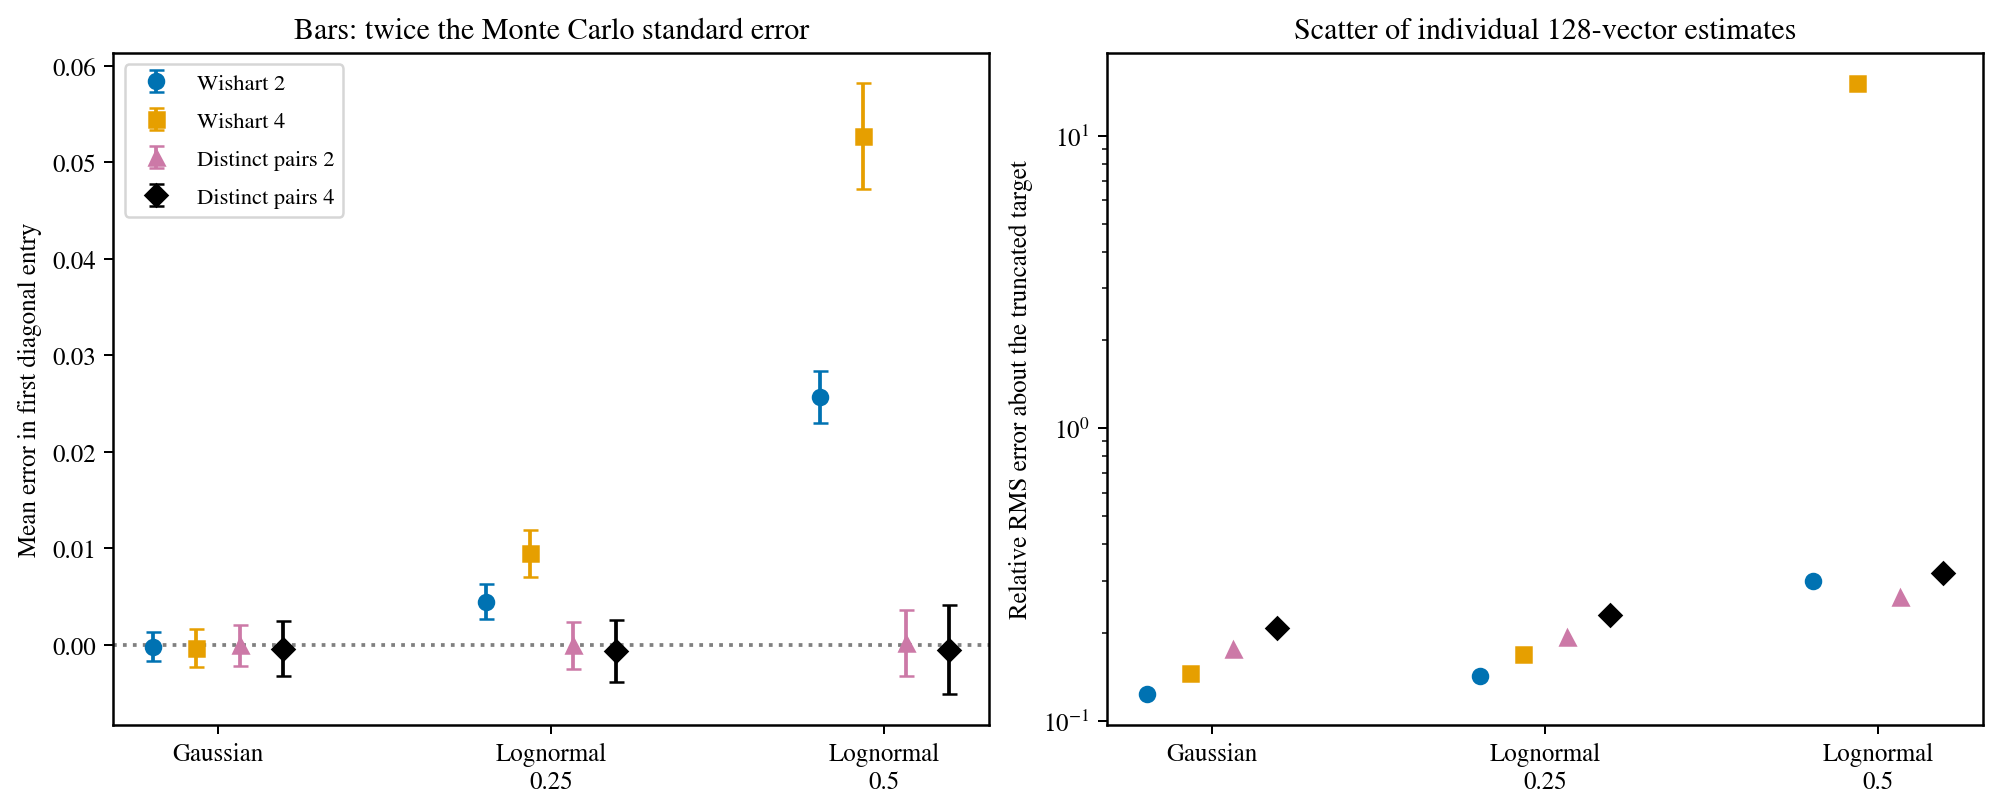

In [25]:
# Show both the mean bias and the variability of individual estimates.
# Different symbols and a colorblind palette keep all four methods distinct.
method_colors = ["#0072B2", "#E69F00", "#CC79A7", "#000000"]
method_markers = ["o", "s", "^", "D"]
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(11, 4.4), constrained_layout=True)
plot_records = []
for method, label in enumerate(toy_methods):
    positions = np.arange(3) + (method - 1.5) * 0.13
    bias = [result[0][method, 0, 0] - toy_targets[method][0, 0] for result in toy_results]
    errors = [result[1][method, 0, 0] for result in toy_results]
    scatter = [result[2][method] for result in toy_results]
    axes[0].errorbar(
        x=positions,
        y=bias,
        yerr=2. * np.array(errors),
        fmt=method_markers[method],
        color=method_colors[method],
        capsize=3,
        label=label,
    )
    axes[1].plot(
        positions,
        scatter,
        marker=method_markers[method],
        linestyle="none",
        color=method_colors[method],
    )
    for case in range(3):
        plot_records.append([
            case, method, bias[case], errors[case], scatter[case],
            toy_results[case][3][method] / toy_repetitions,
        ])
axes[0].axhline(y=0., color="gray", linestyle=":")
axes[0].set_ylabel("Mean error in first diagonal entry")
axes[0].set_title("Bars: twice the Monte Carlo standard error")
axes[0].legend(loc="upper left", fontsize=9)
axes[1].set_yscale("log")
axes[1].set_ylabel("Relative RMS error about the truncated target")
axes[1].set_title("Scatter of individual 128-vector estimates")
for ax in axes:
    ax.set_xticks(
        ticks=np.arange(3),
        labels=["Gaussian", "Lognormal\n0.25", "Lognormal\n0.5"],
    )
plt.show()
# Save only a small teaching table. No simulations or figures are copied
# into data/. The note's figure folder has a frozen copy for redrawing.
toy_output = PROJECT / "chains" / "covariance_fourth_order"
toy_output.mkdir(parents=True, exist_ok=True)
np.savetxt(
    fname=toy_output / "toy_summary.txt",
    X=np.array(plot_records),
    fmt="%.17e",
    header="case method bias_00 mc_sem_00 relative_rmse nonpositive_fraction",
)

## 16. Understand the jackknife before reading the DES error bars

A jackknife asks how sensitive an estimate is to the observed runs. It
recomputes that estimate after omitting one run at a time. It does not
create new independent simulations and does not require a held-out group.
The reported covariance still uses every run.

Try four scalar measurements: $0,1,2,3$. Their ordinary sample variance is
$5/3$. Compare it with a fixed reference variance of $2$: the ratio is
$5/6$. Delete each observation and recompute the variance of the remaining
three numbers, dividing by **two**, not three. The four variance ratios are

$$\left(\frac12,\frac76,\frac76,\frac12\right).$$

Their average is $5/6$. The deviations from that average are

$$\left(-\frac13,\frac13,\frac13,-\frac13\right).$$

The jackknife variance estimate is the sum of squared deviations multiplied
by $(N-1)/N$:

$$V_\mathrm{jack}=\frac34\left(4\times\frac19\right)=\frac13.$$

Its standard error is $1/\sqrt3$. This four-number example teaches the
arithmetic; such a tiny sample does not guarantee well-calibrated error bars.
The notes derive the prefactor with pseudovalues and explain why the
leave-one-out results cannot be treated as independent experiments.

In [26]:
jack_values = np.array([0., 1., 2., 3.])
jack_reference = 2.
jack_full = np.var(a=jack_values, ddof=1) / jack_reference
jack_ratios = []
for omitted in range(len(jack_values)):
    retained = np.delete(arr=jack_values, obj=omitted)
    # ddof=1 automatically changes the denominator to N-2 after deletion.
    ratio = np.var(a=retained, ddof=1) / jack_reference
    jack_ratios.append(ratio)
jack_ratios = np.array(jack_ratios)
jack_center = np.mean(a=jack_ratios)
jack_variance = (len(jack_values) - 1.) / len(jack_values) * np.sum(
    (jack_ratios - jack_center)**2,
)
np.testing.assert_allclose(jack_ratios, [0.5, 7./6., 7./6., 0.5])
np.testing.assert_allclose(jack_variance, 1./3.)
# Pseudovalues make the same variance formula look like variance-of-a-mean.
# For nonlinear statistics they are not independent new data points.
jack_pseudovalues = len(jack_values) * jack_full - (len(jack_values) - 1) * jack_ratios
np.testing.assert_allclose(
    np.var(a=jack_pseudovalues, ddof=1) / len(jack_values),
    jack_variance,
)
print("Full-sample variance ratio:", jack_full)
print("Leave-one-out ratios:", jack_ratios)
print("Jackknife standard error:", np.sqrt(jack_variance))

Full-sample variance ratio: 0.8333333333333334
Leave-one-out ratios: [0.5        1.16666667 1.16666667 0.5       ]
Jackknife standard error: 0.5773502691896258


## 17. Continue to sixth order: two more multiplications
### Keep the target fixed while increasing the polynomial order.
The unknown true matrix remains $R$, the same fixed model defines its
units, and $X=R-I$. Increasing the order changes the approximation to
$R^{-1}$; it does not change what covariance we are estimating. Start
from the fourth residual power already multiplied out:
$$
 X^4=R^4-4R^3+6R^2-4R+I.
$$
Multiply by the first term of $R-I$:
$$
 X^4R=R^5-4R^4+6R^3-4R^2+R.
$$
Multiplying by the second term reverses every sign:
$$
 X^4(-I)=-R^4+4R^3-6R^2+4R-I.
$$
Add the two rows, displaying the coefficient additions:
$$
 X^5=R^5+(-4-1)R^4+(6+4)R^3+(-4-6)R^2+(1+4)R-I.
$$
The simplified fifth power is
$$
 X^5=R^5-5R^4+10R^3-10R^2+5R-I.
$$

### Subtract the fifth power from the fourth-order inverse.
The next inverse-series term has a minus sign:
$$
 P_5=P_4-X^5.
$$
Insert both polynomials before removing brackets:
$$
 \begin{aligned}
 P_5={}&(5I-10R+10R^2-5R^3+R^4)\\
       &-(R^5-5R^4+10R^3-10R^2+5R-I).
 \end{aligned}
$$
Each contribution from the second line changes sign. Collecting the
coefficients in ascending powers gives
$$
 \begin{aligned}
 P_5={}&(5+1)I+(-10-5)R+(10+10)R^2\\
       &+(-5-10)R^3+(1+5)R^4-R^5.
 \end{aligned}
$$
Adding the displayed integers yields
$$
 P_5=6I-15R+20R^2-15R^3+6R^4-R^5.
$$

### Build the sixth residual power before adding it.
Multiply the fifth residual by $R$:
$$
 X^5R=R^6-5R^5+10R^4-10R^3+5R^2-R.
$$
The other product in $X^5(R-I)$ is
$$
 X^5(-I)=-R^5+5R^4-10R^3+10R^2-5R+I.
$$
Adding their coefficients gives
$$
 \begin{aligned}
 X^6={}&R^6+(-5-1)R^5+(10+5)R^4+(-10-10)R^3\\
       &+(5+10)R^2+(-1-5)R+I.
 \end{aligned}
$$
This simplifies to
$$
 X^6=R^6-6R^5+15R^4-20R^3+15R^2-6R+I.
$$
The sixth-order inverse is $P_5+X^6$. The plus sign leaves every
coefficient of the new residual power unchanged:
$$
 \begin{aligned}
 P_6={}&(6+1)I+(-15-6)R+(20+15)R^2\\
       &+(-15-20)R^3+(6+15)R^4+(-1-6)R^5+R^6.
 \end{aligned}
$$
The target polynomial is therefore
$$
 P_6=7I-21R+35R^2-35R^3+21R^4-7R^5+R^6.
$$
For the earlier scalar check, $R=1.2$ and $X=0.2$. Subtracting the fifth
residual power gives
$$
 P_5=0.8336-0.00032=0.83328.
$$
Adding the sixth gives
$$
 P_6=0.83328+0.000064=0.833344.
$$
The exact answer remains $0.83333\ldots$. Smaller truncation error in this
noise-free calculation does not yet imply a better finite-sample estimate.

### Show exactly what must be unbiased.
Under Gaussian sampling, construct $Q_j$ with mean $R^j$ for every degree
through six. The linear combination to evaluate is
$$
 \widehat P_6=7I-21S+35Q_2-35Q_3+21Q_4-7Q_5+Q_6.
$$
Take its expectation term by term, keeping all coefficients:
$$
 \begin{aligned}
 \E[\widehat P_6]={}&7I-21\E[S]+35\E[Q_2]-35\E[Q_3]\\
                   &+21\E[Q_4]-7\E[Q_5]+\E[Q_6].
 \end{aligned}
$$
Insert the defining expectation of each corrected power:
$$
 \E[\widehat P_6]=7I-21R+35R^2-35R^3+21R^4-7R^5+R^6=P_6.
$$
The proof is about the mean of the finite polynomial. It does not assert
that its inverse is unbiased or that every sampled precision is positive.

### How the Gaussian coefficient calculation grows.
At degree five there are twelve matrix/trace expressions; at degree six
there are nineteen. To list them without guessing, choose the matrix
power $r\geq1$, then partition the remaining degree among traces. For
example, at total degree six and $r=3$, the remaining degree is three.
Its partitions are $3$, $2+1$ and $1+1+1$, giving respectively
$$
 S^3\operatorname{tr}(S^3).
$$
The second partition gives
$$
 S^3\operatorname{tr}(S^2)\operatorname{tr}(S).
$$
The third gives
$$
 S^3[\operatorname{tr}(S)]^3.
$$
Repeating this enumeration for $r=1,\ldots,6$ supplies all nineteen terms.
Each contains twelve Gaussian factors. Pair the first factor with one
of eleven partners, the next unused factor with one of nine, and continue:
$$
 11\times9\times7\times5\times3\times1=10395.
$$
Each pairing is evaluated by the same covariance-entry multiplication
used in the earlier noisy-square derivation. Arrange the resulting
expectations as columns of a matrix $A_6(\nu)$. If $c$ lists the nineteen
observed-term coefficients, the equations are
$$
 A_6(\nu)c=(1,0,\ldots,0)^{\mathsf T}.
$$
The first component keeps $R^6$ with unit coefficient; the other eighteen
cancel trace contamination. This is the same linear system construction
and elimination demonstrated in full at cubic order. The accompanying
exact script enumerates every contraction, solves this system symbolically
and verifies all nineteen equations. The formulas used here require
$\nu>5$. The numerical experiment also solves the system in exact rational
arithmetic at its chosen integer $\nu$, before any floating-point sampling.

### Check the sixth-power correction in one dimension.
For the scalar Wishart form $S=RZ/\nu$, the sixth chi-square moment is
$$
 \E[Z^6]=\nu(\nu+2)(\nu+4)(\nu+6)(\nu+8)(\nu+10).
$$
Multiplication by $R^6/\nu^6$ gives the mean of $S^6$:
$$
 \E[S^6]=R^6\frac{(\nu+2)(\nu+4)(\nu+6)(\nu+8)(\nu+10)}{\nu^5}.
$$
Divide the observed sixth power by this known multiplier:
$$
 Q_{6,\mathrm{scalar}}=
 \frac{\nu^5S^6}{(\nu+2)(\nu+4)(\nu+6)(\nu+8)(\nu+10)}.
$$
Summing the nineteen matrix coefficients in one dimension must reproduce
this scalar coefficient. The script checks that identity exactly; it is
an independent normalization check, not a substitute for the matrix proof.

### The distinct-pair construction extends without Gaussian moments.
Keep the factors $B_a=I-z_az_a^{\mathsf T}$ and their mean $U=I-R$.
For six distinct pairs, write one product entry with its five intermediate
indices:
$$
 (B_aB_bB_cB_dB_eB_f)_{ij}
 =\sum_{k_1,\ldots,k_5}
 (B_a)_{ik_1}(B_b)_{k_1k_2}(B_c)_{k_2k_3}
 (B_d)_{k_3k_4}(B_e)_{k_4k_5}(B_f)_{k_5j}.
$$
Independence allows the expectation of each term to be factored into
six separate expectations. Replace each of those expectations by an
entry of $U$, without changing the index order:
$$
 \E[(B_aB_bB_cB_dB_eB_f)_{ij}]
 =\sum_{k_1,\ldots,k_5}
 U_{ik_1}U_{k_1k_2}U_{k_2k_3}U_{k_3k_4}U_{k_4k_5}U_{k_5j}.
$$
The right-hand side is the definition of $(U^6)_{ij}$. Each product now
uses twelve distinct original vectors. Extend the existing recurrence to
$H_5$ and $H_6$, updating from degree six down to one. The estimator is
$$
 \widehat P_{6,\mathrm{pair}}=I+
       \operatorname{sym}(H_1)+\cdots+\operatorname{sym}(H_6).
$$
Its expectation is $I+U+\cdots+U^6=P_6$. No independent calibration or
validation group is consumed by this construction. Independent vectors
and a fixed reference are still required; twelve related files do not
satisfy the proof merely because they have twelve filenames.

### The repeated experiments separate bias from noise.
The same 32,000 repetitions of 128 vectors are evaluated at orders two,
four and six. Gaussian and both lognormal populations retain the same
known covariance, fixed model and random seeds used above. Both estimator
families are evaluated on each complete sample. The Gaussian sixth-order
mean agrees with its truncated target within 0.32 Monte Carlo standard
errors entry by entry. The distinct-pair sixth-order means agree within
1.09 standard errors in all three populations. These are finite numerical
checks accompanying the exact expectation proofs.

For the more skewed lognormal population, the Gaussian-moment sixth-order
relative RMS error about its truncated target is approximately 985. Rare
samples dominate this result; its small-looking mean-discrepancy significance
is caused by an enormous Monte Carlo standard error and is not evidence of
unbiasedness for that non-Gaussian population. The distinct-pair RMS errors
at orders two, four and six are approximately 0.264, 0.318 and 0.336.
Their nonpositive fractions are 0.463%, 0.609% and 0.788%, respectively.
Nothing was clipped or rejected before computing these statistics.

### More simulated skies can help one error but cannot remove another.
Additional independent draws from a fixed generator reduce sampling noise
about that generator's covariance. They do not make its covariance equal
to the N-body covariance. A map generator fitted using a finite simulation
suite carries uncertainty and possible mismatch in that fit. Treating its
millions of generated maps as millions of new independent N-body skies
would discard that uncertainty. The separate GPTG teaching note explains
the map-generation and forward-comparison experiment. Here the conclusion
is narrower: sixth order is available and testable, but it is not an
automatic improvement over a lower-order estimate at fixed sample size.



### Run the same tests through sixth order

The script beside the notes contains the complete exact coefficient solve,
the descending-degree distinct-pair recurrence and the repeat loop. It uses
one worker and reads no DES maps. Running the following cell repeats the
32,000 experiments for each of the three populations. All results are saved
under `chains/covariance_sixth_order/`; the notes retain compact figure data.


In [27]:
# Extend the same experiment to degree six, without changing its population,
# fixed reference, sample size or random seed. This is a bounded toy test.
import runpy
import sys
precision_note = PROJECT / "notes" / "covariance_from_simulations"
if str(precision_note) not in sys.path:
    sys.path.insert(0, str(precision_note))
sixth_experiment = runpy.run_path(
    path_name=str(precision_note / "precision_order_tests.py"),
)
sixth_experiment["main"]()


case 0 rows Wishart 2,4,6; distinct 2,4,6
 [[ 2.84270129e-01  1.23003779e-01  1.27292814e-01  0.00000000e+00
  -2.13806047e-04  7.52122806e-04]
 [ 3.20586853e-01  1.45285241e-01  1.44591303e-01  0.00000000e+00
  -3.16773430e-04  9.88104869e-04]
 [ 3.18106445e-01  1.50425702e-01  1.50302337e-01  0.00000000e+00
  -3.32222586e-04  1.04437553e-03]
 [ 9.45713978e-01  1.75474750e-01  1.75034019e-01  0.00000000e+00
  -8.33815396e-05  1.06504438e-03]
 [ 1.02859356e+00  2.07898370e-01  2.06793100e-01  0.00000000e+00
  -4.31188109e-04  1.41150114e-03]
 [ 1.08647502e+00  2.16426251e-01  2.16247305e-01  0.00000000e+00
  -5.74825951e-04  1.50166224e-03]]


case 1 rows Wishart 2,4,6; distinct 2,4,6
 [[ 1.38917817e+01  1.41882602e-01  1.43622960e-01  0.00000000e+00
   4.43740889e-03  9.18918552e-04]
 [ 1.01696231e+01  1.69445563e-01  1.68361328e-01  0.00000000e+00
   9.44911812e-03  1.20729728e-03]
 [ 9.74329081e+00  1.76831977e-01  1.76647776e-01  0.00000000e+00
   1.14798311e-02  1.28104134e-03]
 [ 8.96435371e-01  1.93117321e-01  1.91375601e-01  6.25000000e-05
  -1.01043792e-04  1.20363398e-03]
 [ 9.55617995e-01  2.29212261e-01  2.27971497e-01  6.25000000e-05
  -6.63125802e-04  1.60202677e-03]
 [ 1.06505716e+00  2.39260582e-01  2.39062370e-01  6.25000000e-05
  -8.88846957e-04  1.70932477e-03]]


case 2 rows Wishart 2,4,6; distinct 2,4,6
 [[ 2.43759438e+01  2.99303499e-01  2.89267084e-01  0.00000000e+00
   2.56423159e-02  1.34491271e-03]
 [ 1.92276362e+01  1.50822891e+01  1.49926894e+01  3.12500000e-05
   5.27265104e-02  2.74222529e-03]
 [ 1.45488157e+00  9.84792423e+02  9.83954630e+02  6.25000000e-05
   1.98414048e-01  1.36378144e-01]
 [ 4.26008564e-01  2.64094370e-01  2.57828575e-01  4.62500000e-03
   1.67574346e-04  1.69947764e-03]
 [ 3.12200243e-01  3.18367488e-01  3.16557334e-01  6.09375000e-03
  -5.47636878e-04  2.30960069e-03]
 [ 5.43307209e-01  3.35662711e-01  3.35380760e-01  7.87500000e-03
  -9.97836042e-04  2.50264904e-03]]


## 18. Can we correct a Kunhao reference again using Rafael's simulations?

This is a **controlled statistical test**, not a DES map calculation. Run these
new cells independently of the earlier expensive experiments. They import only
NumPy and threadpoolctl, use one BLAS worker, and neither generate maps nor run
TreeCorr. The derivation and literature review are in the final section of the
[covariance note](notes/covariance_from_simulations/covariance_from_simulations.pdf).

A first covariance model can come from many cheap simulations. The second stage
must estimate a **new residual relative to that finished model**. It corrects a
precision, not maps or posterior chains. We keep the analytical two-point block
$A$ fixed. The toy has 24 first-block rows and eight second-block rows; these are
random-vector coordinates, not shear measurements.

The matrix factors are formed from independent pair differences. They have the
correct expectation without a Gaussian assumption. Replacing their first block
with $A$ does not make them Wishart covariance draws. Consequently we estimate the
square with **distinct factors**, including both multiplication orders:

$$Q=\frac{(\sum_r T_r)^2-\sum_r T_r^2}{m(m-1)}.$$

Then the second precision polynomial is

$$\widehat\Psi_2=L^{-\mathsf T}(I-\overline T+Q)L^{-1}.$$

Its expectation matches a finite polynomial, not the infinite inverse. The
additional nonlinear reconstruction enforcing exact $A$ has its own bias. The
functions below expose these two steps separately; failed conditional positivity
is recorded rather than repaired by clipping eigenvalues.


In [28]:
import numpy as np
from threadpoolctl import threadpool_limits

blas_limit = threadpool_limits(limits=1, user_api="blas")

# This is a small statistical experiment, not a DES prediction. The first
# 24 rows play the role of xi; the last 8 play the role of Map3. Setting A
# to identity means we have measured the first block in known noise units.
known_rows = 24
map_rows = 8
dimension = known_rows + map_rows
known_A = np.eye(known_rows)
identity = np.eye(dimension)
design_rng = np.random.default_rng(seed=22112026)
true_B = design_rng.normal(scale=0.08, size=(known_rows, map_rows))
true_H = np.diag(np.linspace(start=0.8, stop=1.2, num=map_rows))
truth = np.block([
    [known_A, true_B],
    [true_B.T, true_H + true_B.T @ true_B],
])
truth_chol = np.linalg.cholesky(a=truth)

# A deliberately imperfect cheap model: its cross response is 20% smaller,
# and its conditional Map3 variance 20% larger. These choices are known toy
# discrepancies. They are not measured errors of Kunhao's generator.
cheap_B = 0.8 * true_B
cheap_truth = np.block([
    [known_A, cheap_B],
    [cheap_B.T, 1.2 * true_H + cheap_B.T @ cheap_B],
])
cheap_chol = np.linalg.cholesky(a=cheap_truth)
initial_model = np.block([
    [known_A, np.zeros_like(true_B)],
    [np.zeros_like(true_B.T), 1.8 * true_H],
])


def fixed_A_precision(raw_precision):
    """Preserve the conditional model, then restore the known marginal A.

    Arguments:
      raw_precision = symmetric joint inverse-covariance estimate.
    Returns:
      reconstructed precision, or None if conditional precision is not positive.

    This nonlinear reconstruction is not an unbiasedness correction. It
    enforces the scientific constraint on A; its total error is measured
    against known truth below. No negative eigenvalue is clipped.
    """
    conditional_precision = raw_precision[known_rows:, known_rows:]
    if np.linalg.eigvalsh(a=conditional_precision)[0] <= 0.0:
        return None
    regression = -np.linalg.solve(
        a=conditional_precision,
        b=raw_precision[known_rows:, :known_rows],
    )
    cross_precision = -regression.T @ conditional_precision
    # A=I in this experiment, so A^{-1}=I as well.
    first_precision = known_A + regression.T @ conditional_precision @ regression
    return np.block([
        [first_precision, cross_precision],
        [cross_precision.T, conditional_precision],
    ])


def second_stage_polynomials(vectors, model, use_known_A_control=False):
    """Compute first/second PME using distinct independent pair factors.

    Arguments:
      vectors = independent rows; their count must be even and at least four.
      model = positive reference independent of every input row.
      use_known_A_control = use known x covariance to reduce B/D fluctuations.
    Returns:
      raw first-order and second-order precision polynomials.

    Pair differences remove an unknown mean without Gaussian assumptions.
    Replacing only each factor's A block gives an unbiased matrix factor,
    but not a covariance or a Wishart draw. Distinct products, not a Wishart
    formula for that modified factor, provide the square correction.
    """
    number = len(vectors)
    if number < 4 or number % 2 != 0:
        raise ValueError("Use an even number of independent rows, at least four.")
    differences = (vectors[0::2] - vectors[1::2]) / np.sqrt(2.0)
    factors = differences[:, :, None] * differences[:, None, :]
    if use_known_A_control:
        # R predicts y from x using the independent reference. A fluctuating
        # x covariance has known expectation A. Subtract its predicted
        # effect on B and D; this changes noise, not their expectation.
        regression = model[known_rows:, :known_rows]
        fluctuation = factors[:, :known_rows, :known_rows] - known_A
        factors[:, :known_rows, known_rows:] -= fluctuation @ regression.T
        factors[:, known_rows:, :known_rows] -= regression @ fluctuation
        factors[:, known_rows:, known_rows:] -= (
            regression @ fluctuation @ regression.T
        )
    factors[:, :known_rows, :known_rows] = known_A
    inverse_chol = np.linalg.inv(a=np.linalg.cholesky(a=model))
    residuals = inverse_chol @ (factors - model) @ inverse_chol.T
    count = len(residuals)
    residual_sum = np.sum(a=residuals, axis=0)
    # Squaring the sum includes all ordered products. Subtracting the
    # same-factor squares leaves exactly r != s, including both orders.
    self_squares = np.sum(a=residuals @ residuals, axis=0)
    unbiased_square = (residual_sum @ residual_sum - self_squares)
    unbiased_square /= count * (count - 1)
    first_polynomial = identity - residual_sum / count
    first = inverse_chol.T @ first_polynomial @ inverse_chol
    second = inverse_chol.T @ (first_polynomial + unbiased_square) @ inverse_chol
    return first, second


def precision_error(precision):
    """Return dimensionless RMS precision error against known toy truth.

    Each whitened truth eigenmode should have weight one. This Frobenius
    norm counts all matrix directions; it is not a parameter-error metric.
    """
    residual = truth_chol.T @ precision @ truth_chol - identity
    return np.linalg.norm(x=residual, ord="fro") / np.sqrt(dimension)




### 18.1 Freeze an independently generated reference

The cheap model is deliberately imperfect: its cross block is smaller and its
conditional variance larger than the target's. One ensemble of 10,000 cheap
vectors supplies either direct covariance blocks or a first PME. Both are valid
candidates for a reference; **the first stage does not have to use PME**.

We know the toy population, so we can calculate both reference error and the
spectral radius of the remaining residual. That radius must be below one for the
deterministic expansion to converge. It does not measure sampling noise.


In [29]:
# Freeze one reference ensemble before drawing any expensive target rows.
# Stage one can either use its sample blocks or a PME about an analytic
# model. We compare both; applying PME twice is not a requirement.
cheap_rng = np.random.default_rng(seed=6101)
cheap_rows = cheap_rng.normal(size=(10000, dimension)) @ cheap_chol.T
direct_cheap = np.cov(m=cheap_rows, rowvar=False)
direct_cheap[:known_rows, :known_rows] = known_A
np.linalg.cholesky(a=direct_cheap)
unused_first, cheap_raw_second = second_stage_polynomials(
    vectors=cheap_rows,
    model=initial_model,
)
cheap_precision = fixed_A_precision(raw_precision=cheap_raw_second)
assert cheap_precision is not None
pme_cheap = np.linalg.inv(a=cheap_precision)
references = {
    "analytic": initial_model,
    "cheap direct": direct_cheap,
    "cheap PME2": pme_cheap,
}
print("Frozen references: baseline error and population residual radius")
for name, reference in references.items():
    inverse_chol = np.linalg.inv(a=np.linalg.cholesky(a=reference))
    population_residual = inverse_chol @ (truth - reference) @ inverse_chol.T
    radius = np.max(a=np.abs(np.linalg.eigvalsh(a=population_residual)))
    error = precision_error(precision=np.linalg.inv(a=reference))
    print(f"{name:14s} error={error:.6f} rho={radius:.6f}")



Frozen references: baseline error and population residual radius
analytic       error=0.283617 rho=0.585218
cheap direct   error=0.100925 rho=0.241163
cheap PME2     error=0.131071 rho=0.303049


### 18.2 Give each second-stage estimator the same limited target ensemble

We repeat the experiment 128 times with 200 independent target vectors. Gaussian
and skewed vectors have the same exact covariance. The skewed coordinates are
centered, variance-normalized lognormal random numbers before applying the
Cholesky factor. Each repetition uses the same vectors for all estimators.

For each successful result the known-truth precision error is

$$\epsilon=\|L_R^{\mathsf T}\widehat\Psi L_R-I\|_F/\sqrt{32}.$$

The reported RMS averages its square over positive estimates. **Failures remain
part of the result**; successful-only RMS is not an unconditional risk measure.
The reference ensemble is held fixed, so this experiment does not measure
uncertainty from refitting that reference.

We also test a known-$A$ control. With a regression $R_0$ learned from the
independent cheap reference, define $e=y-R_0x$. Subtracting the known-zero-mean
fluctuation in the first-block sample covariance gives

$$\widehat B=S_{xy}-(S_{xx}-A)R_0^{\mathsf T},$$

and

$$\widehat D=S_{yy}-R_0(S_{xx}-A)R_0^{\mathsf T}.$$

PME uses 100 disjoint-pair factors; direct estimation and shrinkage use the
ordinary sample covariance of all 200 vectors. The simulation budget is the
same, but pairing sacrifices statistical efficiency. This is not a ranking
of optimally efficient PME estimators.

This uses the first and second blocks measured on the **same expensive map**.
It needs no matched GPTG/DES initial conditions. The note derives every
cancellation. A better covariance factor need not yield a better reconstructed
precision, particularly for skewed distributions and near-singular estimates.


In [30]:
# In each repetition, all estimators see the same 200 target vectors.
# Gaussian and skewed distributions have exactly the same covariance.
# A centered, standardized lognormal component has mean zero and variance
# one; multiplying by the truth Cholesky factor imposes the chosen C.
results = []
for distribution in ("Gaussian", "skewed"):
    target_rng = np.random.default_rng(seed=6102)
    errors = {}
    failures = {}
    for name in references:
        for order in (1, 2):
            key = f"{name} PME{order}"
            errors[key] = []
            failures[key] = 0
    errors["target direct"] = []
    failures["target direct"] = 0
    errors["half shrinkage"] = []
    failures["half shrinkage"] = 0
    errors["known A control PME2"] = []
    failures["known A control PME2"] = 0
    for repeat in range(128):
        independent = target_rng.normal(size=(200, dimension))
        if distribution == "skewed":
            independent = np.exp(0.6 * independent) - np.exp(0.18)
            independent /= np.sqrt(np.exp(0.36) * np.expm1(0.36))
        target_rows = independent @ truth_chol.T
        sample = np.cov(m=target_rows, rowvar=False)
        sample[:known_rows, :known_rows] = known_A
        # The shrinkage weight is chosen in advance, not tuned on these
        # realizations or on the known truth. It is only a simple comparator.
        competitors = {
            "target direct": sample,
            "half shrinkage": 0.5 * sample + 0.5 * direct_cheap,
        }
        for name, covariance in competitors.items():
            if np.linalg.eigvalsh(a=covariance)[0] <= 0.0:
                failures[name] += 1
            else:
                errors[name].append(precision_error(
                    precision=np.linalg.inv(a=covariance),
                ))
        for name, reference in references.items():
            polynomials = second_stage_polynomials(
                vectors=target_rows,
                model=reference,
            )
            for order, polynomial in enumerate(polynomials, start=1):
                key = f"{name} PME{order}"
                precision = fixed_A_precision(raw_precision=polynomial)
                if precision is None:
                    failures[key] += 1
                else:
                    # Check the constraint by inversion, not merely by
                    # assuming the reconstruction implemented the algebra.
                    recovered = np.linalg.inv(a=precision)
                    np.testing.assert_allclose(
                        actual=recovered[:known_rows, :known_rows],
                        desired=known_A,
                        atol=1.0e-12,
                    )
                    errors[key].append(precision_error(precision=precision))
        unused_first, controlled_second = second_stage_polynomials(
            vectors=target_rows,
            model=direct_cheap,
            use_known_A_control=True,
        )
        controlled_precision = fixed_A_precision(raw_precision=controlled_second)
        if controlled_precision is None:
            failures["known A control PME2"] += 1
        else:
            errors["known A control PME2"].append(precision_error(
                precision=controlled_precision,
            ))
    print(distribution, "128 repetitions; RMS over positive estimates")
    for name in errors:
        values = np.asarray(a=errors[name])
        rms = np.sqrt(np.mean(a=values**2))
        median = np.median(a=values)
        upper = np.quantile(a=values, q=0.95)
        print(
            f"{name:22s} RMS={rms:.6f} median={median:.6f} "
            f"p95={upper:.6f} failures={failures[name]}/128"
        )
        results.append((distribution, name, rms, failures[name]))



Gaussian 128 repetitions; RMS over positive estimates
analytic PME1          RMS=0.278585 median=0.276209 p95=0.307799 failures=0/128
analytic PME2          RMS=0.323527 median=0.322077 p95=0.350904 failures=0/128
cheap direct PME1      RMS=0.367094 median=0.362895 p95=0.421223 failures=0/128
cheap direct PME2      RMS=0.432448 median=0.430282 p95=0.471322 failures=0/128
cheap PME2 PME1        RMS=0.341675 median=0.337015 p95=0.391426 failures=0/128
cheap PME2 PME2        RMS=0.416745 median=0.415548 p95=0.452668 failures=0/128
target direct          RMS=0.427446 median=0.421370 p95=0.507831 failures=0/128
half shrinkage         RMS=0.142994 median=0.143291 p95=0.154287 failures=0/128
known A control PME2   RMS=0.398718 median=0.396810 p95=0.430750 failures=0/128


skewed 128 repetitions; RMS over positive estimates
analytic PME1          RMS=0.290040 median=0.285845 p95=0.334657 failures=0/128
analytic PME2          RMS=0.340759 median=0.338426 p95=0.377419 failures=1/128
cheap direct PME1      RMS=0.428517 median=0.394966 p95=0.485755 failures=1/128
cheap direct PME2      RMS=0.596678 median=0.458264 p95=0.537388 failures=5/128
cheap PME2 PME1        RMS=0.371402 median=0.360892 p95=0.435358 failures=1/128
cheap PME2 PME2        RMS=0.464297 median=0.441731 p95=0.520145 failures=4/128
target direct          RMS=0.542520 median=0.499110 p95=0.739309 failures=1/128
half shrinkage         RMS=0.153986 median=0.153397 p95=0.172828 failures=0/128
known A control PME2   RMS=0.819947 median=0.422174 p95=0.506808 failures=3/128


### 18.3 Why the full dimensionality still matters

The toy above is not a 480-entry forecast. We can nevertheless solve one
480-entry noise example exactly: population and reference both equal identity,
with 400 known first-block rows and 80 corrected rows. Even when the reference
has no error, a first-order correction fluctuates.

There are $2pq$ cross entries in the symmetric matrix. The second block adds
$q(q+1)$ units of Gaussian covariance-estimation variance. Therefore

$$\epsilon_\mathrm{raw,1}^2=\frac{2pq+q(q+1)}{(p+q)\nu}.$$

For ordinary sample covariance $\nu=N-1$; for disjoint pairs it is $N/2$.
This is a raw full-matrix precision norm, **not a parameter-error prediction**.
It explains why fixing $A$ does not automatically make an unrestricted correction
from approximately 200 parents quiet enough.


In [31]:
# A separate exact calculation exposes the high-dimensional noise cost.
# This is first-order precision noise at C=M=I, BEFORE reconstruction.
# There are 2*p*q cross entries and q*(q+1) units of variance in D.
p = 400
q = 80
number = 200
numerator = 2 * p * q + q * (q + 1)
ordinary_rms = np.sqrt(numerator / ((p + q) * (number - 1)))
pair_rms = np.sqrt(numerator / ((p + q) * (number // 2)))
print("480-row Gaussian identity example: raw first-order RMS")
print(f"ordinary sample: {ordinary_rms:.6f}; independent pairs: {pair_rms:.6f}")
print("Expected direct fixed-A Schur diagonal:", 1.0 - p / (number - 1))



480-row Gaussian identity example: raw first-order RMS
ordinary sample: 0.858985; independent pairs: 1.211748
Expected direct fixed-A Schur diagonal: -1.0100502512562812


### 18.4 Check the algebra and the dependence problem separately

First enumerate all ordered products for four matrices and compare with the
compact noisy-square expression. Then test the known-$A$ control on the scalar
Gaussian model $y=x+e$, with independent unit-variance $x,e$. Its predicted
variance ratios are $1/3$ for the cross estimate and $3/4$ for the second variance.
These are covariance-entry checks, before any nonlinear inversion.

Finally let a cheap model learn its variance from the very expensive sample it
will later correct: $M_G=S_R$. With infinitely many cheap maps, first-order PME
still becomes $1/S_R$. For twenty Gaussian target vectors its expected value is
$19/17$ when the true precision is one. New cheap seeds do not remove training
reuse. This is directly relevant: the present GPTG point functions and noise
calibration used Rafael parents 0000–0031.


In [32]:
# Independent algebra checks: explicitly enumerate ordered products of
# four symmetric matrices. Matrix multiplication is not elementwise.
check_rng = np.random.default_rng(seed=6103)
small = check_rng.normal(size=(4, 3, 3))
small = 0.5 * (small + np.swapaxes(a=small, axis1=1, axis2=2))
explicit = np.zeros(shape=(3, 3))
for first in range(4):
    for second in range(4):
        if first != second:
            explicit += small[first] @ small[second]
total = np.sum(a=small, axis=0)
compact = total @ total - np.sum(a=small @ small, axis=0)
np.testing.assert_allclose(actual=compact, desired=explicit, atol=1.0e-13)

# Here x and e are independent standard Gaussians, and y=x+e. Known
# Var(x)=1 and regression R0=1 let us remove sample-variance noise from B.
# This checks covariance entries before any noisy inversion/reconstruction.
scalar_rng = np.random.default_rng(seed=6104)
x = scalar_rng.normal(size=(10000, 200))
e = scalar_rng.normal(size=(10000, 200))
x -= np.mean(a=x, axis=1, keepdims=True)
e -= np.mean(a=e, axis=1, keepdims=True)
y = x + e
sxx = np.sum(a=x * x, axis=1) / 199.0
sxy = np.sum(a=x * y, axis=1) / 199.0
syy = np.sum(a=y * y, axis=1) / 199.0
controlled_b = sxy - (sxx - 1.0)
controlled_d = syy - (sxx - 1.0)
b_ratio = np.var(a=controlled_b) / np.var(a=sxy)
d_ratio = np.var(a=controlled_d) / np.var(a=syy)
print("Known-A scalar control: measured B,D variance ratios", b_ratio, d_ratio)
print("Exact Gaussian variance ratios", 1.0 / 3.0, 3.0 / 4.0)
assert abs(b_ratio - 1.0 / 3.0) < 0.03
assert abs(d_ratio - 3.0 / 4.0) < 0.04

# Reusing calibration data: let the cheap model variance equal the target
# sample variance. Infinite cheap simulations then determine that fitted
# number perfectly, but leave its sampling bias relative to true variance.
variances = scalar_rng.chisquare(df=19, size=50000) / 19.0
inverse_mean = np.mean(a=1.0 / variances)
print("Reused-reference inverse mean", inverse_mean, "exact", 19.0 / 17.0)
assert abs(inverse_mean - 19.0 / 17.0) < 0.01
print("Ordered-product, fixed-A, scalar-control and leakage checks passed.")


Known-A scalar control: measured B,D variance ratios 0.3397225925704757 0.7555784693852797
Exact Gaussian variance ratios 0.3333333333333333 0.75
Reused-reference inverse mean 1.1177358450377326 exact 1.1176470588235294
Ordered-product, fixed-A, scalar-control and leakage checks passed.


### 18.5 What to take forward

In this test a better cheap reference makes the population residual smaller,
but applying an unrestricted second PME makes the final estimate noisier.
The simple half-weight shrinkage comparator does better than those corrections;
the reference alone does best for this particular stipulated mismatch. Neither
result selects a DES method. The control-variate scalar gain is real, but the
skewed multivariate test warns against assuming it survives inversion unchanged.

The next map-level experiment needs **two unequal generators**, matched
measurements, repeated expensive-sized ensembles, and independent target
validation. Test model mismatch, fitting overlap, positivity and parameter
coverage. Use all eligible expensive parents for correction; there is no need
to split the scarce DES ensemble into three permanent groups.

The frozen present reference can first be checked against parents outside its
32-parent calibration, once producer identities are confirmed. Local Rafael
measurements are not yet a matching full joint vector. Their multiple footprint
and noise labels must not be counted as independent parent universes.

Relevant primary papers:
[Friedrich–Eifler PME](https://arxiv.org/abs/1703.07786),
[Hall–Taylor covariance priors](https://arxiv.org/abs/1807.06875),
[Pope–Szapudi shrinkage](https://arxiv.org/abs/0711.2509),
[CARPool covariance](https://arxiv.org/abs/2106.11718),
[CARPool Bayes](https://arxiv.org/abs/2204.03070),
[Sellentin–Heavens likelihood](https://arxiv.org/abs/1511.05969), and
[Zhong et al. GPTG](https://arxiv.org/abs/2411.04759).
